<a href="https://colab.research.google.com/github/ThisumiWijesinghe/SMS_SPAM_DETECTION_ANN/blob/main/Neural_Netwrok.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Import Libraries

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
import requests



#2. Download the dataset from UCI repository

In [ ]:

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

response = requests.get(url, timeout=60)
response.raise_for_status()

# Check that the downloaded content is a ZIP file
assert response.content[:2] == b"PK", (
    "The downloaded file does not appear to be a ZIP archive."
)

with ZipFile(BytesIO(response.content)) as zip_file:
    print("Files available in the ZIP:")
    for filename in zip_file.namelist():
        print("-", filename)

    # Find the original message file
    dataset_file = next(
        name for name in zip_file.namelist()
        if Path(name).name == "SMSSpamCollection"
    )

    # Read the original tab-separated data
    with zip_file.open(dataset_file) as file:
        df = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=["label", "message"],
            encoding="utf-8"
        )

print("\nDataset downloaded and loaded successfully!")
print("Dataset shape:", df.shape)


Files available in the ZIP:
- SMSSpamCollection
- readme

Dataset downloaded and loaded successfully!
Dataset shape: (5572, 2)


#3. Inspect the dataset

In [ ]:

print("First 10 messages:")
display(df.head(10))

print("\nDataset dimensions:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()


First 10 messages:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...



Dataset dimensions:
Rows: 5572
Columns: 2

Column names:
['label', 'message']

Data types:
label      object
message    object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


#4. Check the target variables and class imbalance

Unique labels:
['ham' 'spam']

Class counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Class percentages:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


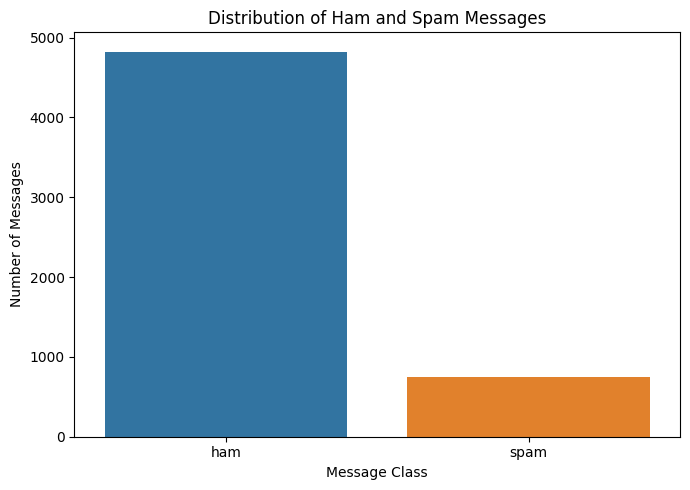

In [ ]:
print("Unique labels:")
print(df["label"].unique())

label_counts = df["label"].value_counts()

print("\nClass counts:")
print(label_counts)

print("\nClass percentages:")
print((df["label"].value_counts(normalize=True) * 100).round(2))

# Visualise class distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="label", hue="label", legend=False)

plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message Class")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()


#5. Check the missing values , duplicates and data quality

In [ ]:

# Cell 5: Data quality checks

print("Missing values per column:")
print(df.isnull().sum())

print("\nCompletely duplicated rows:")
print(df.duplicated().sum())

print("\nDuplicated message texts:")
print(df["message"].duplicated().sum())

print("\nEmpty or whitespace-only messages:")
print(df["message"].str.strip().eq("").sum())

print("\nUnexpected labels:")
print(sorted(set(df["label"].unique()) - {"ham", "spam"}))


Missing values per column:
label      0
message    0
dtype: int64

Completely duplicated rows:
403

Duplicated message texts:
403

Empty or whitespace-only messages:
0

Unexpected labels:
[]


#6. Find out the length of mesage for class

In [ ]:

df["character_count"] = df["message"].str.len()

df["word_count"] = df["message"].apply(
    lambda message: len(message.split())
)

print("Message length statistics:")
display(
    df.groupby("label")[["character_count", "word_count"]]
      .describe()
      .round(2)
)


Message length statistics:


character_count                                                   \
                count    mean    std   min    25%    50%    75%    max   
label                                                                    
ham            4825.0   71.48  58.44   2.0   33.0   52.0   93.0  910.0   
spam            747.0  138.67  28.87  13.0  133.0  149.0  157.0  223.0   

      word_count                                              
           count   mean    std  min   25%   50%   75%    max  
label                                                         
ham       4825.0  14.31  11.52  1.0   7.0  11.0  19.0  171.0  
spam       747.0  23.91   5.78  2.0  22.0  25.0  28.0   35.0

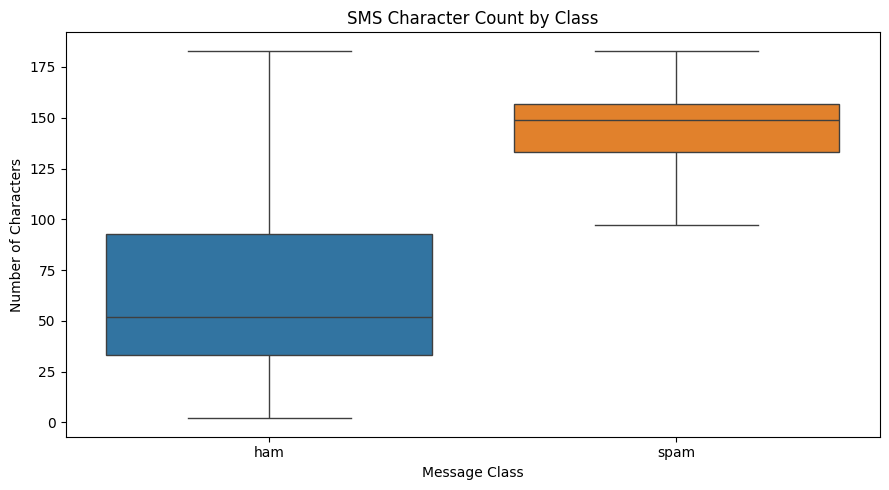

In [ ]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="label",
    y="character_count",
    hue="label",
    legend=False,
    showfliers=False
)

plt.title("SMS Character Count by Class")
plt.xlabel("Message Class")
plt.ylabel("Number of Characters")
plt.tight_layout()
plt.show()

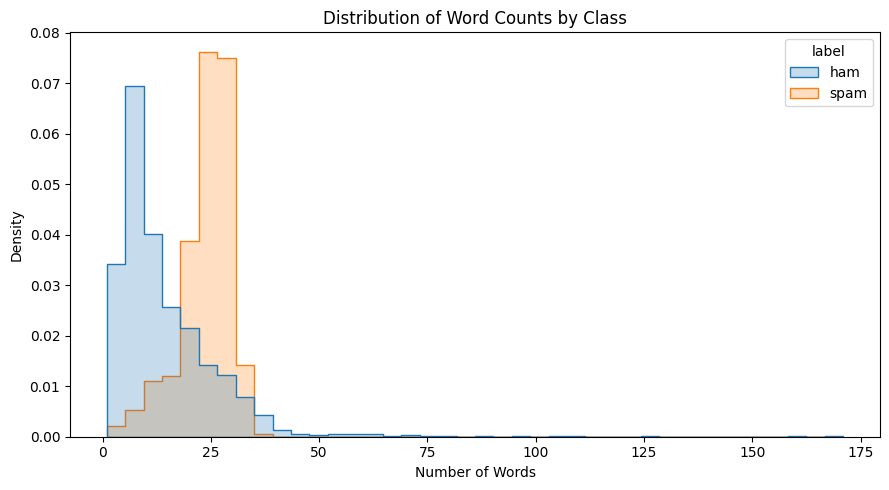

In [ ]:

#Compare word counts by class

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="word_count",
    hue="label",
    bins=40,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Distribution of Word Counts by Class")
plt.xlabel("Number of Words")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


In [ ]:

print("Examples of legitimate messages (ham):")
display(
    df.loc[df["label"] == "ham", ["label", "message"]].head(5)
)

print("\nExamples of spam messages:")
display(
    df.loc[df["label"] == "spam", ["label", "message"]].head(5)
)


Examples of legitimate messages (ham):


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
6,ham,Even my brother is not like to speak with me. ...



Examples of spam messages:


,label,message
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
5,spam,FreeMsg Hey there darling it's been 3 week's n...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...
11,spam,"SIX chances to win CASH! From 100 to 20,000 po..."


#7. Save the Loaded dataset

In [ ]:

# Save the loaded dataset and exploratory copy

output_dir = Path("/content/sms_spam_project")
output_dir.mkdir(parents=True, exist_ok=True)

# Preserve the original two columns separately
df[["label", "message"]].to_csv(
    output_dir / "sms_spam_original.csv",
    index=False
)

# Save the exploratory version with message lengths
df.to_csv(
    output_dir / "sms_spam_exploration.csv",
    index=False
)

print("Files saved to:", output_dir)
print("\nSaved files:")
for path in sorted(output_dir.iterdir()):
    print(path.name, "-", path.stat().st_size, "bytes")



# Final data quality summary

print("Total messages:", len(df))
print("Missing values:", df[["label", "message"]].isnull().sum().sum())
print("Duplicate rows:", df[["label", "message"]].duplicated().sum())
print("Empty messages:", df["message"].str.strip().eq("").sum())
print("Class counts:\n", df["label"].value_counts())



Files saved to: /content/sms_spam_project

Saved files:
sms_spam_exploration.csv - 513837 bytes
sms_spam_original.csv - 480806 bytes
Total messages: 5572
Missing values: 0
Duplicate rows: 403
Empty messages: 0
Class counts:
 label
ham     4825
spam     747
Name: count, dtype: int64


# Step 2 : 1. Preprocessing Part

In [ ]:

# Clean the dataset and create train/validation/test sets

from sklearn.model_selection import train_test_split

# 1. Keep only the original columns
data = df[["label", "message"]].copy()

print("Original dataset size:", len(data))

# 2. Remove exact duplicate rows
data = data.drop_duplicates(subset=["label", "message"]).reset_index(drop=True)

print("Dataset size after removing exact duplicates:", len(data))
print("Duplicates remaining:", data.duplicated(subset=["label", "message"]).sum())

# 3. Encode labels: ham = 0, spam = 1
data["target"] = data["label"].map({"ham": 0, "spam": 1})

# Verify the encoding
print("\nLabel mapping:")
print({"ham": 0, "spam": 1})

print("\nClass counts after cleaning:")
print(data["label"].value_counts())

# 4. Separate text and target
X = data["message"]
y = data["target"]

# 5. Split off 15% for the final test set
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# 6. Split the remaining 85% into training and validation.
# This gives approximately 70% train, 15% validation, 15% test.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.1764705882,
    random_state=42,
    stratify=y_train_val
)

# 7. Display split sizes
print("\nSplit sizes:")
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))
print("Total:", len(X_train) + len(X_val) + len(X_test))

# 8. Check class proportions in each split
split_summary = pd.DataFrame({
    "Training": y_train.value_counts(normalize=True),
    "Validation": y_val.value_counts(normalize=True),
    "Testing": y_test.value_counts(normalize=True)
}).T.rename(columns={0: "ham proportion", 1: "spam proportion"})

print("\nClass proportions in each split:")
display((split_summary * 100).round(2))


Original dataset size: 5572
Dataset size after removing exact duplicates: 5169
Duplicates remaining: 0

Label mapping:
{'ham': 0, 'spam': 1}

Class counts after cleaning:
label
ham     4516
spam     653
Name: count, dtype: int64

Split sizes:
Training: 3617
Validation: 776
Testing: 776
Total: 5169

Class proportions in each split:


target,ham proportion,spam proportion
Training,87.37,12.63
Validation,87.37,12.63
Testing,87.37,12.63


#2. Save cleaned data and split information

In [ ]:


from pathlib import Path
import json
import platform
import pandas as pd
import sklearn

# Create project folder
output_dir = Path("/content/sms_spam_project")
output_dir.mkdir(parents=True, exist_ok=True)

# Check that the existing splits are available
assert len(X_train) == len(y_train), "Training data and labels do not match"
assert len(X_val) == len(y_val), "Validation data and labels do not match"
assert len(X_test) == len(y_test), "Testing data and labels do not match"

# Check that all samples are accounted for
assert len(X_train) + len(X_val) + len(X_test) == len(data)

# Check for overlapping row indices between splits
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

# Save cleaned dataset
data.to_csv(output_dir / "sms_spam_cleaned.csv", index=False)

# Save the indices used for each split
pd.Series(X_train.index, name="row_index").to_csv(
    output_dir / "train_indices.csv", index=False
)
pd.Series(X_val.index, name="row_index").to_csv(
    output_dir / "validation_indices.csv", index=False
)
pd.Series(X_test.index, name="row_index").to_csv(
    output_dir / "test_indices.csv", index=False
)

# Save a combined split manifest
split_manifest = pd.concat([
    pd.DataFrame({"row_index": X_train.index, "split": "train"}),
    pd.DataFrame({"row_index": X_val.index, "split": "validation"}),
    pd.DataFrame({"row_index": X_test.index, "split": "test"})
], ignore_index=True)

split_manifest.to_csv(
    output_dir / "split_manifest.csv", index=False
)

# Save settings for reproducibility
settings = {
    "dataset": "UCI SMS Spam Collection",
    "source": "https://archive.ics.uci.edu/dataset/228/sms+spam+collection",
    "original_rows": 5572,
    "cleaned_rows": len(data),
    "duplicates_removed": 403,
    "label_mapping": {"ham": 0, "spam": 1},
    "split_sizes": {
        "train": len(X_train),
        "validation": len(X_val),
        "test": len(X_test)
    },
    "split_method": "Stratified train_test_split",
    "random_state": 42,
    "python_version": platform.python_version(),
    "pandas_version": pd.__version__,
    "scikit_learn_version": sklearn.__version__
}

with open(output_dir / "experiment_settings.json", "w") as f:
    json.dump(settings, f, indent=4)

print("Data and split information saved successfully.")
print("Project folder:", output_dir)
print("\nSaved files:")
for file_path in sorted(output_dir.iterdir()):
    print("-", file_path.name)

Data and split information saved successfully.
Project folder: /content/sms_spam_project

Saved files:
- experiment_settings.json
- sms_spam_cleaned.csv
- sms_spam_exploration.csv
- sms_spam_original.csv
- split_manifest.csv
- test_indices.csv
- train_indices.csv
- validation_indices.csv


# 3. Text preprocessing

In [ ]:
#Text preprocessing using TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer
from pathlib import Path
import joblib

# Create the vectorizer
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words=None,
    ngram_range=(1, 2),
    max_features=10000,
    sublinear_tf=True
)

# Fit ONLY on the training messages
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation and test messages using the fitted vectorizer
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF preprocessing completed.")
print("Training feature shape:", X_train_tfidf.shape)
print("Validation feature shape:", X_val_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)
print("Number of vocabulary terms:", len(tfidf.vocabulary_))

# Save the fitted vectorizer for reproducibility
joblib.dump(tfidf, output_dir / "tfidf_vectorizer.joblib")

TF-IDF preprocessing completed.
Training feature shape: (3617, 10000)
Validation feature shape: (776, 10000)
Testing feature shape: (776, 10000)
Number of vocabulary terms: 10000


['/content/sms_spam_project/tfidf_vectorizer.joblib']

#4. Train a baseline machine-learning model

Validation Results — Logistic Regression
-----------------------------------------
Accuracy:  0.9601
Precision: 1.0000
Recall:    0.6837
F1-score:  0.8121

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       678
        Spam       1.00      0.68      0.81        98

    accuracy                           0.96       776
   macro avg       0.98      0.84      0.89       776
weighted avg       0.96      0.96      0.96       776



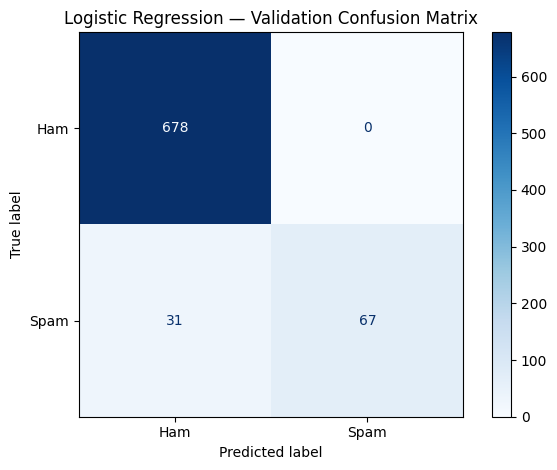

['/content/sms_spam_project/logistic_regression_baseline.joblib']

In [ ]:
# Step 3: Train a Logistic Regression baseline

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import json

# Train on training data only
baseline_model = LogisticRegression(
    max_iter=1000,
    class_weight=None,
    random_state=42
)

baseline_model.fit(X_train_tfidf, y_train)

# Evaluate on the validation set first
val_predictions = baseline_model.predict(X_val_tfidf)

print("Validation Results — Logistic Regression")
print("-----------------------------------------")
print(f"Accuracy:  {accuracy_score(y_val, val_predictions):.4f}")
print(f"Precision: {precision_score(y_val, val_predictions, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_val, val_predictions, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_val, val_predictions, zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    val_predictions,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    zero_division=0
))

# Plot validation confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_predictions,
    labels=[0, 1],
    display_labels=["Ham", "Spam"],
    cmap="Blues"
)
plt.title("Logistic Regression — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

# Save the trained baseline model
joblib.dump(baseline_model, output_dir / "logistic_regression_baseline.joblib")

#5. save baseline validation results

In [ ]:

baseline_metrics = {
    "model": "Logistic Regression",
    "evaluation_set": "validation",
    "accuracy": float(accuracy_score(y_val, val_predictions)),
    "precision_spam": float(
        precision_score(y_val, val_predictions, zero_division=0)
    ),
    "recall_spam": float(
        recall_score(y_val, val_predictions, zero_division=0)
    ),
    "f1_spam": float(
        f1_score(y_val, val_predictions, zero_division=0)
    )
}

with open(output_dir / "baseline_validation_metrics.json", "w") as f:
    json.dump(baseline_metrics, f, indent=4)

print("Baseline validation metrics saved.")
print(json.dumps(baseline_metrics, indent=4))

Baseline validation metrics saved.
{
    "model": "Logistic Regression",
    "evaluation_set": "validation",
    "accuracy": 0.9600515463917526,
    "precision_spam": 1.0,
    "recall_spam": 0.6836734693877551,
    "f1_spam": 0.8121212121212121
}


# Prepare features for the numpy MLP

In [ ]:


from sklearn.decomposition import TruncatedSVD
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import json

required = [
    "X_train_tfidf",
    "X_val_tfidf",
    "y_train",
    "y_val",
    "output_dir"
]

for name in required:
    assert name in globals(), f"Run the earlier cell that creates {name}"

svd = TruncatedSVD(
    n_components=32,
    random_state=42
)

X_train_numpy = svd.fit_transform(
    X_train_tfidf
).astype(np.float64)

X_val_numpy = svd.transform(
    X_val_tfidf
).astype(np.float64)

y_train_numpy = np.asarray(
    y_train,
    dtype=np.float64
).reshape(-1, 1)

y_val_numpy = np.asarray(
    y_val,
    dtype=np.float64
).reshape(-1, 1)

joblib.dump(
    svd,
    output_dir / "numpy_svd.joblib"
)

print("Training features:", X_train_numpy.shape)
print("Validation features:", X_val_numpy.shape)
print("Training targets:", y_train_numpy.shape)

Training features: (3617, 32)
Validation features: (776, 32)
Training targets: (3617, 1)


# Define the NumPy neural network

In [ ]:


def initialise_parameters(input_size, hidden_size=16, seed=42):
    rng = np.random.default_rng(seed)

    return {
        "W1": rng.normal(
            0,
            np.sqrt(1 / input_size),
            (input_size, hidden_size)
        ),
        "b1": np.zeros((1, hidden_size)),
        "W2": rng.normal(
            0,
            np.sqrt(1 / hidden_size),
            (hidden_size, 1)
        ),
        "b2": np.zeros((1, 1))
    }


def forward_pass(X, parameters):
    Z1 = X @ parameters["W1"] + parameters["b1"]
    H = np.tanh(Z1)

    logits = H @ parameters["W2"] + parameters["b2"]

    probabilities = np.exp(
        -np.logaddexp(0, -logits)
    )

    return H, logits, probabilities


def loss_and_gradients(X, y, parameters):
    H, logits, probabilities = forward_pass(
        X,
        parameters
    )

    loss = np.mean(
        np.logaddexp(0, logits) - y * logits
    )

    dZ2 = (probabilities - y) / len(X)

    dW2 = H.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dZ1 = (
        dZ2 @ parameters["W2"].T
    ) * (1 - H ** 2)

    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    gradients = {
        "W1": dW1,
        "b1": db1,
        "W2": dW2,
        "b2": db2
    }

    return float(loss), gradients


parameters = initialise_parameters(
    X_train_numpy.shape[1]
)

print("Parameter shapes:")

for name, values in parameters.items():
    print(name, values.shape)

Parameter shapes:
W1 (32, 16)
b1 (1, 16)
W2 (16, 1)
b2 (1, 1)


# Verify analytical gradients

In [ ]:
X_check = X_train_numpy[:8]
y_check = y_train_numpy[:8]

_, analytical_gradients = loss_and_gradients(
    X_check,
    y_check,
    parameters
)

epsilon = 1e-5

entries = [
    ("W1", (0, 0)),
    ("W1", (1, 1)),
    ("b1", (0, 0)),
    ("W2", (0, 0)),
    ("b2", (0, 0))
]

gradient_results = []

for name, index in entries:
    original_value = parameters[name][index]

    parameters[name][index] = original_value + epsilon

    loss_plus, _ = loss_and_gradients(
        X_check,
        y_check,
        parameters
    )

    parameters[name][index] = original_value - epsilon

    loss_minus, _ = loss_and_gradients(
        X_check,
        y_check,
        parameters
    )

    parameters[name][index] = original_value

    numerical = (
        loss_plus - loss_minus
    ) / (2 * epsilon)

    analytical = float(
        analytical_gradients[name][index]
    )

    absolute_error = abs(
        analytical - numerical
    )

    relative_error = absolute_error / max(
        1e-8,
        abs(analytical) + abs(numerical)
    )

    passed = (
        absolute_error < 1e-7
        or relative_error < 1e-4
    )

    gradient_results.append({
        "parameter": name,
        "index": str(index),
        "analytical": analytical,
        "numerical": numerical,
        "absolute_error": absolute_error,
        "relative_error": relative_error,
        "epsilon": epsilon,
        "passed": passed
    })

gradient_table = pd.DataFrame(
    gradient_results
)

display(gradient_table)

gradient_table.to_csv(
    output_dir / "numpy_gradient_check.csv",
    index=False
)

assert gradient_table["passed"].all(), (
    "Gradient verification failed."
)

print("All five gradient checks passed.")

,parameter,index,analytical,numerical,absolute_error,relative_error,epsilon,passed
0,W1,"(0, 0)",0.001647,0.001647,3.211693e-12,9.748535e-10,0.00001,True
1,W1,"(1, 1)",0.000081,0.000081,2.889449e-12,1.786602e-08,0.00001,True
2,b1,"(0, 0)",0.012491,0.012491,6.519407e-12,2.609625e-10,0.00001,True
3,W2,"(0, 0)",-0.010717,-0.010717,3.244644e-12,1.513838e-10,0.00001,True
4,b2,"(0, 0)",0.503372,0.503372,2.646772e-12,2.629043e-12,0.00001,True


All five gradient checks passed.


# Train the NumPy MLP

Epoch 001 | Train loss: 0.3795 | Validation loss: 0.3800
Epoch 010 | Train loss: 0.3421 | Validation loss: 0.3443
Epoch 020 | Train loss: 0.2368 | Validation loss: 0.2429
Epoch 030 | Train loss: 0.1474 | Validation loss: 0.1568
Epoch 040 | Train loss: 0.1149 | Validation loss: 0.1261
Epoch 050 | Train loss: 0.1017 | Validation loss: 0.1134
Epoch 060 | Train loss: 0.0957 | Validation loss: 0.1073
Epoch 070 | Train loss: 0.0916 | Validation loss: 0.1032
Epoch 080 | Train loss: 0.0895 | Validation loss: 0.1010
Epoch 090 | Train loss: 0.0903 | Validation loss: 0.1010
Epoch 100 | Train loss: 0.0871 | Validation loss: 0.0980


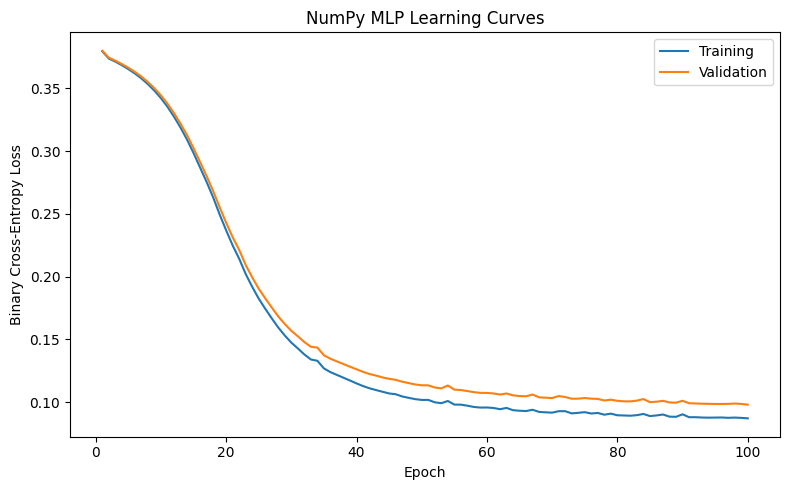

Initial training loss: 0.6943548816867683
Final training loss: 0.087059524888891


In [ ]:
parameters = initialise_parameters(
    input_size=X_train_numpy.shape[1],
    hidden_size=16,
    seed=42
)

learning_rate = 0.1
batch_size = 64
epochs = 100

rng = np.random.default_rng(42)
history = []

initial_loss, _ = loss_and_gradients(
    X_train_numpy,
    y_train_numpy,
    parameters
)

for epoch in range(epochs):
    indices = rng.permutation(
        len(X_train_numpy)
    )

    for start in range(
        0,
        len(indices),
        batch_size
    ):
        batch_indices = indices[
            start:start + batch_size
        ]

        _, gradients = loss_and_gradients(
            X_train_numpy[batch_indices],
            y_train_numpy[batch_indices],
            parameters
        )

        for name in parameters:
            parameters[name] -= (
                learning_rate * gradients[name]
            )

    train_loss, _ = loss_and_gradients(
        X_train_numpy,
        y_train_numpy,
        parameters
    )

    val_loss, _ = loss_and_gradients(
        X_val_numpy,
        y_val_numpy,
        parameters
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "validation_loss": val_loss
    })

    if epoch == 0 or (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1:03d} | "
            f"Train loss: {train_loss:.4f} | "
            f"Validation loss: {val_loss:.4f}"
        )

history_df = pd.DataFrame(history)

history_df.to_csv(
    output_dir / "numpy_training_history.csv",
    index=False
)

np.savez(
    output_dir / "numpy_mlp_parameters.npz",
    **parameters
)

numpy_settings = {
    "input_features": X_train_numpy.shape[1],
    "hidden_neurons": 16,
    "hidden_activation": "tanh",
    "output_activation": "sigmoid",
    "loss": "binary cross-entropy",
    "optimiser": "mini-batch gradient descent",
    "learning_rate": learning_rate,
    "batch_size": batch_size,
    "seed": 42,
    "stopping_rule": "fixed 100 epochs",
    "actual_epochs": len(history_df),
    "initial_train_loss": initial_loss,
    "final_train_loss": train_loss,
    "final_validation_loss": val_loss
}

with open(
    output_dir / "numpy_mlp_settings.json",
    "w"
) as file:
    json.dump(numpy_settings, file, indent=4)

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training"
)

plt.plot(
    history_df["epoch"],
    history_df["validation_loss"],
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("NumPy MLP Learning Curves")
plt.legend()
plt.tight_layout()

plt.savefig(
    output_dir / "numpy_learning_curves.png",
    dpi=200
)

plt.show()

print("Initial training loss:", initial_loss)
print("Final training loss:", train_loss)

# Evaluate the NumPy MLP on validation data

In [ ]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

_, _, numpy_val_probabilities = forward_pass(
    X_val_numpy,
    parameters
)

numpy_val_predictions = (
    numpy_val_probabilities.ravel() >= 0.5
).astype(int)

numpy_val_targets = y_val_numpy.ravel().astype(int)

print(
    classification_report(
        numpy_val_targets,
        numpy_val_predictions,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

numpy_validation_metrics = {
    "model": "NumPy MLP",
    "evaluation_set": "validation",
    "accuracy": float(
        accuracy_score(
            numpy_val_targets,
            numpy_val_predictions
        )
    ),
    "precision_spam": float(
        precision_score(
            numpy_val_targets,
            numpy_val_predictions,
            zero_division=0
        )
    ),
    "recall_spam": float(
        recall_score(
            numpy_val_targets,
            numpy_val_predictions,
            zero_division=0
        )
    ),
    "f1_spam": float(
        f1_score(
            numpy_val_targets,
            numpy_val_predictions,
            zero_division=0
        )
    )
}

with open(
    output_dir / "numpy_validation_metrics.json",
    "w"
) as file:
    json.dump(
        numpy_validation_metrics,
        file,
        indent=4
    )

              precision    recall  f1-score   support

         Ham       0.97      0.98      0.98       678
        Spam       0.87      0.79      0.82        98

    accuracy                           0.96       776
   macro avg       0.92      0.88      0.90       776
weighted avg       0.96      0.96      0.96       776



# Tiny-batch overfitting diagnostic


{
    "samples": 16,
    "learning_rate": 0.3,
    "maximum_updates": 3000,
    "actual_updates": 464,
    "stopping_rule": "loss <= 0.03 or 3000 updates",
    "initial_loss": 0.7019925139826759,
    "final_loss": 0.029884437409734784,
    "target_reached": true
}


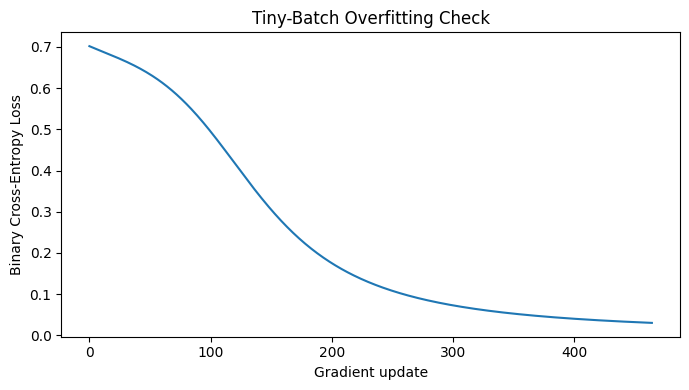

The model successfully fitted the tiny batch.


In [ ]:

flat_targets = y_train_numpy.ravel()

tiny_indices = np.concatenate([
    np.flatnonzero(flat_targets == 0)[:8],
    np.flatnonzero(flat_targets == 1)[:8]
])

X_tiny = X_train_numpy[tiny_indices]
y_tiny = y_train_numpy[tiny_indices]

tiny_parameters = initialise_parameters(
    input_size=X_tiny.shape[1],
    hidden_size=32,
    seed=123
)

tiny_lr = 0.3
max_updates = 3000
target_loss = 0.03
updates = 0
tiny_losses = []

tiny_initial_loss, _ = loss_and_gradients(
    X_tiny,
    y_tiny,
    tiny_parameters
)

for step in range(max_updates):
    loss, gradients = loss_and_gradients(
        X_tiny,
        y_tiny,
        tiny_parameters
    )

    tiny_losses.append(loss)

    if loss <= target_loss:
        break

    for name in tiny_parameters:
        tiny_parameters[name] -= (
            tiny_lr * gradients[name]
        )

    updates += 1

tiny_final_loss, _ = loss_and_gradients(
    X_tiny,
    y_tiny,
    tiny_parameters
)

diagnostic = {
    "samples": len(X_tiny),
    "learning_rate": tiny_lr,
    "maximum_updates": max_updates,
    "actual_updates": updates,
    "stopping_rule": "loss <= 0.03 or 3000 updates",
    "initial_loss": tiny_initial_loss,
    "final_loss": tiny_final_loss,
    "target_reached": bool(
        tiny_final_loss <= target_loss
    )
}

with open(
    output_dir / "numpy_tiny_batch_check.json",
    "w"
) as file:
    json.dump(diagnostic, file, indent=4)

print(json.dumps(diagnostic, indent=4))

plt.figure(figsize=(7, 4))
plt.plot(tiny_losses)
plt.xlabel("Gradient update")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Tiny-Batch Overfitting Check")
plt.tight_layout()

plt.savefig(
    output_dir / "numpy_tiny_batch_curve.png",
    dpi=200
)

plt.show()

if diagnostic["target_reached"]:
    print("The model successfully fitted the tiny batch.")
else:
    print(
        "The target was not reached. "
        "Report this and inspect the learning curve."
    )

# Step 4: Build the Pytorch MLP

## Set up the PyTorch MLP

In [ ]:


import random
import time
import copy
import platform

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEEDS = [11, 22, 33]

MLP_CONFIG = {
    "hidden_sizes": [64, 32],
    "dropout": 0.3,
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "batch_size": 64,
    "max_epochs": 30,
    "patience": 5,
    "min_delta": 0.00001,
    "threshold": 0.5
}

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


environment = {
    "python": platform.python_version(),
    "pytorch": torch.__version__,
    "device": str(device),
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    )
}

with open(
    output_dir / "pytorch_environment.json",
    "w"
) as file:
    json.dump(environment, file, indent=4)

with open(
    output_dir / "pytorch_mlp_config.json",
    "w"
) as file:
    json.dump(
        {
            "settings": MLP_CONFIG,
            "seeds": SEEDS,
            "selection": "Minimum validation loss",
            "tuning_budget": "One prespecified configuration",
            "primary_metric": "Spam F1 at threshold 0.5"
        },
        file,
        indent=4
    )

print(environment)

{'python': '3.13.16', 'pytorch': '2.11.0+cpu', 'device': 'cpu', 'gpu': None}


## Prepare training and validation tensors

In [ ]:
def dense_float32(features):
    if hasattr(features, "toarray"):
        features = features.toarray()

    return np.asarray(features, dtype=np.float32)


X_train_mlp = torch.from_numpy(
    dense_float32(X_train_tfidf)
)

X_val_mlp = torch.from_numpy(
    dense_float32(X_val_tfidf)
)

y_train_mlp = torch.tensor(
    np.asarray(y_train),
    dtype=torch.float32
).reshape(-1)

y_val_mlp = torch.tensor(
    np.asarray(y_val),
    dtype=torch.float32
).reshape(-1)

train_dataset = TensorDataset(
    X_train_mlp,
    y_train_mlp
)

validation_dataset = TensorDataset(
    X_val_mlp,
    y_val_mlp
)

print("Training input:", X_train_mlp.shape)
print("Validation input:", X_val_mlp.shape)
print("Training target:", y_train_mlp.shape)

Training input: torch.Size([3617, 10000])
Validation input: torch.Size([776, 10000])
Training target: torch.Size([3617])


## Deifne the MLP architecture

In [ ]:
class SpamMLP(nn.Module):
    def __init__(
        self,
        input_size,
        hidden_sizes,
        dropout
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, hidden_sizes[0]),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_sizes[0], hidden_sizes[1]),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_sizes[1], 1)
        )

        self.apply(self.initialise_weights)

    @staticmethod
    def initialise_weights(layer):
        if isinstance(layer, nn.Linear):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, features):
        return self.network(features).squeeze(-1)


set_seed(SEEDS[0])

example_model = SpamMLP(
    input_size=X_train_mlp.shape[1],
    hidden_sizes=MLP_CONFIG["hidden_sizes"],
    dropout=MLP_CONFIG["dropout"]
)

print(example_model)

print(
    "Trainable parameters:",
    sum(
        parameter.numel()
        for parameter in example_model.parameters()
        if parameter.requires_grad
    )
)

layer_records = []
example_input = X_train_mlp[:2]

with torch.no_grad():
    example_model.eval()

    for index, layer in enumerate(
        example_model.network
    ):
        input_shape = tuple(example_input.shape)
        example_input = layer(example_input)

        layer_records.append({
            "layer": index + 1,
            "type": type(layer).__name__,
            "input_shape": str(input_shape),
            "output_shape": str(
                tuple(example_input.shape)
            ),
            "parameters": sum(
                parameter.numel()
                for parameter in layer.parameters()
            )
        })

layer_table = pd.DataFrame(layer_records)

display(layer_table)

layer_table.to_csv(
    output_dir / "pytorch_mlp_layers.csv",
    index=False
)

SpamMLP(
  (network): Sequential(
    (0): Linear(in_features=10000, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
Trainable parameters: 642177


,layer,type,input_shape,output_shape,parameters
0,1,Linear,"(2, 10000)","(2, 64)",640064
1,2,ReLU,"(2, 64)","(2, 64)",0
2,3,Dropout,"(2, 64)","(2, 64)",0
3,4,Linear,"(2, 64)","(2, 32)",2080
4,5,ReLU,"(2, 32)","(2, 32)",0
5,6,Dropout,"(2, 32)","(2, 32)",0
6,7,Linear,"(2, 32)","(2, 1)",33


## Train with validation-based early stopping

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


def train_pytorch_mlp(seed):
    set_seed(seed)

    model = SpamMLP(
        input_size=X_train_mlp.shape[1],
        hidden_sizes=MLP_CONFIG["hidden_sizes"],
        dropout=MLP_CONFIG["dropout"]
    ).to(device)

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=MLP_CONFIG["batch_size"],
        shuffle=True,
        generator=generator
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=MLP_CONFIG["batch_size"],
        shuffle=False
    )

    criterion = nn.BCEWithLogitsLoss()

    optimiser = torch.optim.Adam(
        model.parameters(),
        lr=MLP_CONFIG["learning_rate"],
        weight_decay=MLP_CONFIG["weight_decay"]
    )

    best_loss = float("inf")
    best_state = None
    best_epoch = 0
    patience_count = 0
    history = []

    checkpoint_path = (
        output_dir / f"pytorch_mlp_seed_{seed}.pt"
    )

    start_time = time.perf_counter()

    for epoch in range(
        MLP_CONFIG["max_epochs"]
    ):
        model.train()
        train_loss_sum = 0.0

        for features, targets in train_loader:
            features = features.to(device)
            targets = targets.to(device)

            optimiser.zero_grad()

            logits = model(features)
            loss = criterion(logits, targets)

            loss.backward()
            optimiser.step()

            train_loss_sum += (
                loss.item() * len(targets)
            )

        train_loss = (
            train_loss_sum / len(train_dataset)
        )

        model.eval()
        validation_loss_sum = 0.0

        with torch.no_grad():
            for features, targets in validation_loader:
                features = features.to(device)
                targets = targets.to(device)

                logits = model(features)
                loss = criterion(logits, targets)

                validation_loss_sum += (
                    loss.item() * len(targets)
                )

        validation_loss = (
            validation_loss_sum
            / len(validation_dataset)
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "validation_loss": validation_loss
        })

        print(
            f"Seed {seed} | "
            f"Epoch {epoch + 1:02d} | "
            f"Train: {train_loss:.4f} | "
            f"Validation: {validation_loss:.4f}"
        )

        if (
            validation_loss
            < best_loss - MLP_CONFIG["min_delta"]
        ):
            best_loss = validation_loss
            best_epoch = epoch + 1
            patience_count = 0

            best_state = {
                name: value.detach().cpu().clone()
                for name, value
                in model.state_dict().items()
            }

            torch.save(
                best_state,
                checkpoint_path
            )

        else:
            patience_count += 1

        if (
            patience_count
            >= MLP_CONFIG["patience"]
        ):
            print("Early stopping.")
            break

    if device.type == "cuda":
        torch.cuda.synchronize()

    training_seconds = (
        time.perf_counter() - start_time
    )

    model.load_state_dict(best_state)
    model.eval()

    probabilities = []

    with torch.no_grad():
        for features, _ in validation_loader:
            logits = model(
                features.to(device)
            )

            probabilities.extend(
                torch.sigmoid(logits)
                .cpu()
                .numpy()
                .tolist()
            )

    probabilities = np.asarray(probabilities)

    predictions = (
        probabilities >= MLP_CONFIG["threshold"]
    ).astype(int)

    targets = y_val_mlp.numpy().astype(int)

    result = {
        "model": "PyTorch MLP",
        "evaluation_set": "validation",
        "seed": seed,
        "accuracy": float(
            accuracy_score(targets, predictions)
        ),
        "precision_spam": float(
            precision_score(
                targets,
                predictions,
                zero_division=0
            )
        ),
        "recall_spam": float(
            recall_score(
                targets,
                predictions,
                zero_division=0
            )
        ),
        "f1_spam": float(
            f1_score(
                targets,
                predictions,
                zero_division=0
            )
        ),
        "best_epoch": best_epoch,
        "actual_epochs": len(history),
        "best_validation_loss": best_loss,
        "training_seconds": training_seconds,
        "checkpoint": checkpoint_path.name
    }

    history_frame = pd.DataFrame(history)

    history_frame.to_csv(
        output_dir / f"pytorch_mlp_history_{seed}.csv",
        index=False
    )

    with open(
        output_dir / f"pytorch_mlp_run_{seed}.json",
        "w"
    ) as file:
        json.dump(
            {
                "configuration": MLP_CONFIG,
                "input_size": X_train_mlp.shape[1],
                "result": result
            },
            file,
            indent=4
        )

    return result, history_frame

## Run the MLP with three random seeds

In [ ]:
mlp_results = []
mlp_histories = {}

for seed in SEEDS:
    print("\n" + "=" * 55)
    print("Training PyTorch MLP — seed", seed)
    print("=" * 55)

    result, history_frame = train_pytorch_mlp(
        seed
    )

    mlp_results.append(result)
    mlp_histories[seed] = history_frame

mlp_results_df = pd.DataFrame(mlp_results)

mlp_results_df.to_csv(
    output_dir / "pytorch_mlp_validation_results.csv",
    index=False
)

display(mlp_results_df)

metric_columns = [
    "accuracy",
    "precision_spam",
    "recall_spam",
    "f1_spam"
]

mlp_summary = (
    mlp_results_df[metric_columns]
    .agg(["mean", "std"])
    .T
)

mlp_summary.to_csv(
    output_dir / "pytorch_mlp_validation_summary.csv"
)

print("Validation mean and sample standard deviation:")
display(mlp_summary)


Training PyTorch MLP — seed 11
Seed 11 | Epoch 01 | Train: 0.5089 | Validation: 0.2795
Seed 11 | Epoch 02 | Train: 0.1831 | Validation: 0.1294
Seed 11 | Epoch 03 | Train: 0.0721 | Validation: 0.0691
Seed 11 | Epoch 04 | Train: 0.0255 | Validation: 0.0639
Seed 11 | Epoch 05 | Train: 0.0127 | Validation: 0.0629
Seed 11 | Epoch 06 | Train: 0.0072 | Validation: 0.0633
Seed 11 | Epoch 07 | Train: 0.0062 | Validation: 0.0624
Seed 11 | Epoch 08 | Train: 0.0046 | Validation: 0.0647
Seed 11 | Epoch 09 | Train: 0.0045 | Validation: 0.0633
Seed 11 | Epoch 10 | Train: 0.0042 | Validation: 0.0664
Seed 11 | Epoch 11 | Train: 0.0039 | Validation: 0.0647
Seed 11 | Epoch 12 | Train: 0.0037 | Validation: 0.0644
Early stopping.

Training PyTorch MLP — seed 22
Seed 22 | Epoch 01 | Train: 0.5123 | Validation: 0.2785
Seed 22 | Epoch 02 | Train: 0.1796 | Validation: 0.1238
Seed 22 | Epoch 03 | Train: 0.0671 | Validation: 0.0710
Seed 22 | Epoch 04 | Train: 0.0290 | Validation: 0.0625
Seed 22 | Epoch 05 | Tra

,model,evaluation_set,seed,accuracy,precision_spam,recall_spam,f1_spam,best_epoch,actual_epochs,best_validation_loss,training_seconds,checkpoint
0,PyTorch MLP,validation,11,0.981959,0.977273,0.877551,0.924731,7,12,0.062450,13.821047,pytorch_mlp_seed_11.pt
1,PyTorch MLP,validation,22,0.980670,0.956044,0.887755,0.920635,20,25,0.058056,16.282979,pytorch_mlp_seed_22.pt
2,PyTorch MLP,validation,33,0.980670,0.966292,0.877551,0.919786,7,12,0.056319,8.728246,pytorch_mlp_seed_33.pt


Validation mean and sample standard deviation:


,mean,std
accuracy,0.981100,0.000744
precision_spam,0.966536,0.010616
recall_spam,0.880952,0.005891
f1_spam,0.921717,0.002644


## Plot training and validation losses

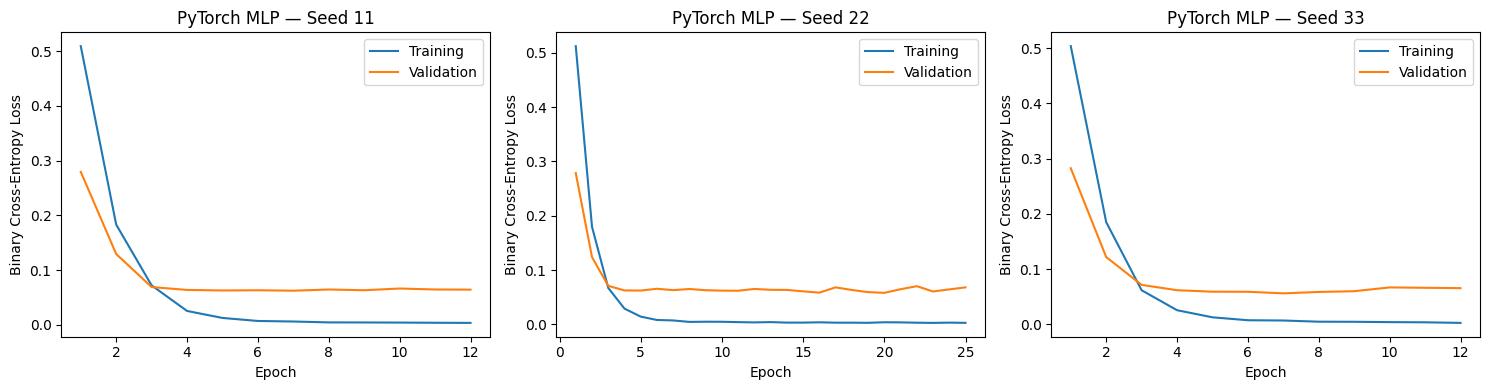

In [ ]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4)
)

for axis, seed in zip(axes, SEEDS):
    history_frame = mlp_histories[seed]

    axis.plot(
        history_frame["epoch"],
        history_frame["train_loss"],
        label="Training"
    )

    axis.plot(
        history_frame["epoch"],
        history_frame["validation_loss"],
        label="Validation"
    )

    axis.set_title(f"PyTorch MLP — Seed {seed}")
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Binary Cross-Entropy Loss")
    axis.legend()

plt.tight_layout()

plt.savefig(
    output_dir / "pytorch_mlp_learning_curves.png",
    dpi=200
)

plt.show()

#Step 5: Build up the Text CNN

## Prepare the Text CNN vocabulary

In [ ]:
import re
from collections import Counter

CNN_CONFIG = {
    "max_vocabulary": 10000,
    "max_length": 80,
    "embedding_dimension": 32,
    "filters": 32,
    "kernel_size": 3,
    "dropout": 0.3,
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "batch_size": 64,
    "max_epochs": 30,
    "patience": 5,
    "min_delta": 0.00001,
    "threshold": 0.5
}

CNN_SEEDS = [11, 22, 33]


def tokenise_sms(message):
    return re.findall(
        r"\w+|[^\w\s]",
        str(message).lower()
    )


token_counts = Counter(
    token
    for message in X_train
    for token in tokenise_sms(message)
)

cnn_vocabulary = {
    token: index + 2
    for index, (token, count) in enumerate(
        token_counts.most_common(
            CNN_CONFIG["max_vocabulary"] - 2
        )
    )
}

cnn_vocabulary_size = len(cnn_vocabulary) + 2

with open(
    output_dir / "cnn_vocabulary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        cnn_vocabulary,
        file,
        indent=4,
        ensure_ascii=False
    )

with open(
    output_dir / "text_cnn_config.json",
    "w"
) as file:
    json.dump(
        {
            "settings": CNN_CONFIG,
            "seeds": CNN_SEEDS,
            "vocabulary_size": cnn_vocabulary_size,
            "padding_id": 0,
            "unknown_id": 1,
            "tokenisation": "Lowercase word/punctuation regex",
            "selection": "Minimum validation loss",
            "tuning_budget": "One prespecified configuration",
            "pretrained_embeddings": False
        },
        file,
        indent=4
    )

print("Vocabulary size:", cnn_vocabulary_size)
print("Maximum sequence length:", CNN_CONFIG["max_length"])

Vocabulary size: 7232
Maximum sequence length: 80


## Encode training and validation messages


In [ ]:


def encode_sms_messages(messages):
    sequences = np.zeros(
        (
            len(messages),
            CNN_CONFIG["max_length"]
        ),
        dtype=np.int64
    )

    for index, message in enumerate(messages):
        token_ids = [
            cnn_vocabulary.get(token, 1)
            for token in tokenise_sms(message)
        ]

        token_ids = token_ids[
            :CNN_CONFIG["max_length"]
        ]

        sequences[index, :len(token_ids)] = token_ids

    return sequences


X_train_cnn = torch.from_numpy(
    encode_sms_messages(X_train)
)

X_val_cnn = torch.from_numpy(
    encode_sms_messages(X_val)
)

y_train_cnn = torch.tensor(
    np.asarray(y_train),
    dtype=torch.float32
).reshape(-1)

y_val_cnn = torch.tensor(
    np.asarray(y_val),
    dtype=torch.float32
).reshape(-1)

cnn_train_dataset = TensorDataset(
    X_train_cnn,
    y_train_cnn
)

cnn_validation_dataset = TensorDataset(
    X_val_cnn,
    y_val_cnn
)

train_lengths = np.array([
    len(tokenise_sms(message))
    for message in X_train
])

print("Training sequences:", X_train_cnn.shape)
print("Validation sequences:", X_val_cnn.shape)

print(
    "Training messages truncated:",
    int(
        (
            train_lengths
            > CNN_CONFIG["max_length"]
        ).sum()
    )
)
print("Example token IDs:", X_train_cnn[0][:20])

Training sequences: torch.Size([3617, 80])
Validation sequences: torch.Size([776, 80])
Training messages truncated: 24
Example token IDs: tensor([186,   2,   2,   2,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0])


## Define the textCNN architecture

In [ ]:
class SpamTextCNN(nn.Module):
    def __init__(
        self,
        vocabulary_size,
        embedding_dimension,
        filters,
        kernel_size,
        dropout
    ):
        super().__init__()

        self.kernel_size = kernel_size

        self.embedding = nn.Embedding(
            num_embeddings=vocabulary_size,
            embedding_dim=embedding_dimension,
            padding_idx=0
        )

        self.convolution = nn.Conv1d(
            in_channels=embedding_dimension,
            out_channels=filters,
            kernel_size=kernel_size
        )

        self.activation = nn.ReLU()
        self.dropout = nn.Dropout(dropout)

        self.output = nn.Linear(
            filters,
            1
        )

        nn.init.normal_(
            self.embedding.weight,
            mean=0.0,
            std=0.1
        )

        with torch.no_grad():
            self.embedding.weight[0].zero_()

        nn.init.xavier_uniform_(
            self.convolution.weight
        )
        nn.init.zeros_(
            self.convolution.bias
        )

        nn.init.xavier_uniform_(
            self.output.weight
        )
        nn.init.zeros_(
            self.output.bias
        )

    def forward(self, token_ids):
        embedded = self.embedding(token_ids)

        features = embedded.transpose(1, 2)

        features = self.activation(
            self.convolution(features)
        )

        valid_windows = (
            token_ids.ne(0)
            .unfold(
                dimension=1,
                size=self.kernel_size,
                step=1
            )
            .any(dim=-1)
            .unsqueeze(1)
        )

        features = features.masked_fill(
            ~valid_windows,
            torch.finfo(features.dtype).min
        )

        pooled = features.amax(dim=2)

        pooled = torch.where(
            valid_windows.any(dim=2),
            pooled,
            torch.zeros_like(pooled)
        )

        logits = self.output(
            self.dropout(pooled)
        )

        return logits.squeeze(-1)


def create_text_cnn():
    return SpamTextCNN(
        vocabulary_size=cnn_vocabulary_size,
        embedding_dimension=CNN_CONFIG[
            "embedding_dimension"
        ],
        filters=CNN_CONFIG["filters"],
        kernel_size=CNN_CONFIG["kernel_size"],
        dropout=CNN_CONFIG["dropout"]
    )


set_seed(CNN_SEEDS[0])

cnn_example = create_text_cnn()

print(cnn_example)

print(
    "Trainable parameters:",
    sum(
        parameter.numel()
        for parameter in cnn_example.parameters()
        if parameter.requires_grad
    )
)

SpamTextCNN(
  (embedding): Embedding(7232, 32, padding_idx=0)
  (convolution): Conv1d(32, 32, kernel_size=(3,), stride=(1,))
  (activation): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (output): Linear(in_features=32, out_features=1, bias=True)
)
Trainable parameters: 234561


## Save CNN layer shapes and parameter counts

In [ ]:
cnn_layer_records = []

example_tokens = X_train_cnn[:2]

with torch.no_grad():
    cnn_example.eval()

    embedded = cnn_example.embedding(example_tokens)

    convolution_input = embedded.transpose(1, 2)

    convolution_output = cnn_example.convolution(
        convolution_input
    )

    activated = cnn_example.activation(
        convolution_output
    )

    pooled = activated.amax(dim=2)

    dropped = cnn_example.dropout(pooled)

    output = cnn_example.output(dropped)


def layer_record(name, inputs, outputs, module=None):
    return {
        "layer": name,
        "input_shape": str(tuple(inputs.shape)),
        "output_shape": str(tuple(outputs.shape)),
        "parameters": (
            sum(
                parameter.numel()
                for parameter in module.parameters()
            )
            if module is not None
            else 0
        )
    }


cnn_layer_records = [
    layer_record(
        "Embedding",
        example_tokens,
        embedded,
        cnn_example.embedding
    ),
    layer_record(
        "Transpose",
        embedded,
        convolution_input
    ),
    layer_record(
        "Conv1D",
        convolution_input,
        convolution_output,
        cnn_example.convolution
    ),
    layer_record(
        "ReLU",
        convolution_output,
        activated
    ),
    layer_record(
        "Masked global max pooling",
        activated,
        pooled
    ),
    layer_record(
        "Dropout",
        pooled,
        dropped
    ),
    layer_record(
        "Linear output",
        dropped,
        output,
        cnn_example.output
    )
]

cnn_layer_table = pd.DataFrame(
    cnn_layer_records
)

display(cnn_layer_table)

cnn_layer_table.to_csv(
    output_dir / "text_cnn_layers.csv",
    index=False
)

,layer,input_shape,output_shape,parameters
0,Embedding,"(2, 80)","(2, 80, 32)",231424
1,Transpose,"(2, 80, 32)","(2, 32, 80)",0
2,Conv1D,"(2, 32, 80)","(2, 32, 78)",3104
3,ReLU,"(2, 32, 78)","(2, 32, 78)",0
4,Masked global max pooling,"(2, 32, 78)","(2, 32)",0
5,Dropout,"(2, 32)","(2, 32)",0
6,Linear output,"(2, 32)","(2, 1)",33


## Train the Text CNN with early stopping

In [ ]:


def train_text_cnn(seed):
    set_seed(seed)

    model = create_text_cnn().to(device)

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        cnn_train_dataset,
        batch_size=CNN_CONFIG["batch_size"],
        shuffle=True,
        generator=generator
    )

    validation_loader = DataLoader(
        cnn_validation_dataset,
        batch_size=CNN_CONFIG["batch_size"],
        shuffle=False
    )

    criterion = nn.BCEWithLogitsLoss()

    optimiser = torch.optim.Adam(
        model.parameters(),
        lr=CNN_CONFIG["learning_rate"],
        weight_decay=CNN_CONFIG["weight_decay"]
    )

    best_loss = float("inf")
    best_state = None
    best_epoch = 0
    patience_count = 0
    history = []

    checkpoint_path = (
        output_dir / f"text_cnn_seed_{seed}.pt"
    )

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    for epoch in range(
        CNN_CONFIG["max_epochs"]
    ):
        model.train()
        training_loss_sum = 0.0

        for features, targets in train_loader:
            features = features.to(device)
            targets = targets.to(device)

            optimiser.zero_grad()

            logits = model(features)
            loss = criterion(logits, targets)

            loss.backward()
            optimiser.step()

            training_loss_sum += (
                loss.item() * len(targets)
            )

        training_loss = (
            training_loss_sum
            / len(cnn_train_dataset)
        )

        model.eval()
        validation_loss_sum = 0.0

        with torch.no_grad():
            for features, targets in validation_loader:
                features = features.to(device)
                targets = targets.to(device)

                logits = model(features)
                loss = criterion(logits, targets)

                validation_loss_sum += (
                    loss.item() * len(targets)
                )

        validation_loss = (
            validation_loss_sum
            / len(cnn_validation_dataset)
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": training_loss,
            "validation_loss": validation_loss
        })

        print(
            f"Seed {seed} | "
            f"Epoch {epoch + 1:02d} | "
            f"Train: {training_loss:.4f} | "
            f"Validation: {validation_loss:.4f}"
        )

        if (
            validation_loss
            < best_loss - CNN_CONFIG["min_delta"]
        ):
            best_loss = validation_loss
            best_epoch = epoch + 1
            patience_count = 0

            best_state = {
                name: value.detach().cpu().clone()
                for name, value
                in model.state_dict().items()
            }

            torch.save(
                best_state,
                checkpoint_path
            )

        else:
            patience_count += 1

        if (
            patience_count
            >= CNN_CONFIG["patience"]
        ):
            print("Early stopping.")
            break

    if device.type == "cuda":
        torch.cuda.synchronize()

    training_seconds = (
        time.perf_counter() - start_time
    )

    model.load_state_dict(best_state)
    model.eval()

    probabilities = []

    with torch.no_grad():
        for features, _ in validation_loader:
            logits = model(
                features.to(device)
            )

            probabilities.extend(
                torch.sigmoid(logits)
                .cpu()
                .numpy()
                .tolist()
            )

    probabilities = np.asarray(probabilities)

    predictions = (
        probabilities >= CNN_CONFIG["threshold"]
    ).astype(int)

    targets = y_val_cnn.numpy().astype(int)

    result = {
        "model": "Text CNN",
        "evaluation_set": "validation",
        "seed": seed,
        "accuracy": float(
            accuracy_score(targets, predictions)
        ),
        "precision_spam": float(
            precision_score(
                targets,
                predictions,
                zero_division=0
            )
        ),
        "recall_spam": float(
            recall_score(
                targets,
                predictions,
                zero_division=0
            )
        ),
        "f1_spam": float(
            f1_score(
                targets,
                predictions,
                zero_division=0
            )
        ),
        "best_epoch": best_epoch,
        "actual_epochs": len(history),
        "best_validation_loss": best_loss,
        "training_seconds": training_seconds,
        "checkpoint": checkpoint_path.name
    }

    history_frame = pd.DataFrame(history)

    history_frame.to_csv(
        output_dir / f"text_cnn_history_{seed}.csv",
        index=False
    )

    with open(
        output_dir / f"text_cnn_run_{seed}.json",
        "w"
    ) as file:
        json.dump(
            {
                "configuration": CNN_CONFIG,
                "vocabulary_size": cnn_vocabulary_size,
                "result": result
            },
            file,
            indent=4
        )

    return result, history_frame

## Run the Text CNN with three seeds

In [ ]:
cnn_results = []
cnn_histories = {}

for seed in CNN_SEEDS:
    print("\n" + "=" * 55)
    print("Training Text CNN — seed", seed)
    print("=" * 55)

    result, history_frame = train_text_cnn(seed)

    cnn_results.append(result)
    cnn_histories[seed] = history_frame

cnn_results_df = pd.DataFrame(cnn_results)

cnn_results_df.to_csv(
    output_dir / "text_cnn_validation_results.csv",
    index=False
)

display(cnn_results_df)

cnn_summary = (
    cnn_results_df[
        [
            "accuracy",
            "precision_spam",
            "recall_spam",
            "f1_spam"
        ]
    ]
    .agg(["mean", "std"])
    .T
)

cnn_summary.to_csv(
    output_dir / "text_cnn_validation_summary.csv"
)

print("Validation mean and sample standard deviation:")
display(cnn_summary)


Training Text CNN — seed 11
Seed 11 | Epoch 01 | Train: 0.5633 | Validation: 0.4059
Seed 11 | Epoch 02 | Train: 0.3508 | Validation: 0.3093
Seed 11 | Epoch 03 | Train: 0.2576 | Validation: 0.2219
Seed 11 | Epoch 04 | Train: 0.1640 | Validation: 0.1418
Seed 11 | Epoch 05 | Train: 0.1028 | Validation: 0.1020
Seed 11 | Epoch 06 | Train: 0.0702 | Validation: 0.0826
Seed 11 | Epoch 07 | Train: 0.0524 | Validation: 0.0731
Seed 11 | Epoch 08 | Train: 0.0401 | Validation: 0.0659
Seed 11 | Epoch 09 | Train: 0.0298 | Validation: 0.0625
Seed 11 | Epoch 10 | Train: 0.0248 | Validation: 0.0600
Seed 11 | Epoch 11 | Train: 0.0208 | Validation: 0.0581
Seed 11 | Epoch 12 | Train: 0.0187 | Validation: 0.0560
Seed 11 | Epoch 13 | Train: 0.0134 | Validation: 0.0565
Seed 11 | Epoch 14 | Train: 0.0124 | Validation: 0.0569
Seed 11 | Epoch 15 | Train: 0.0132 | Validation: 0.0559
Seed 11 | Epoch 16 | Train: 0.0089 | Validation: 0.0571
Seed 11 | Epoch 17 | Train: 0.0087 | Validation: 0.0571
Seed 11 | Epoch 18 

,model,evaluation_set,seed,accuracy,precision_spam,recall_spam,f1_spam,best_epoch,actual_epochs,best_validation_loss,training_seconds,checkpoint
0,Text CNN,validation,11,0.985825,0.967742,0.918367,0.942408,18,23,0.055059,13.796457,text_cnn_seed_11.pt
1,Text CNN,validation,22,0.989691,0.968750,0.948980,0.958763,17,22,0.043173,13.066936,text_cnn_seed_22.pt
2,Text CNN,validation,33,0.985825,0.967742,0.918367,0.942408,18,23,0.047786,13.583400,text_cnn_seed_33.pt


Validation mean and sample standard deviation:


,mean,std
accuracy,0.987113,0.002232
precision_spam,0.968078,0.000582
recall_spam,0.928571,0.017674
f1_spam,0.947860,0.009442


## Plot CNN curves and compare validation results





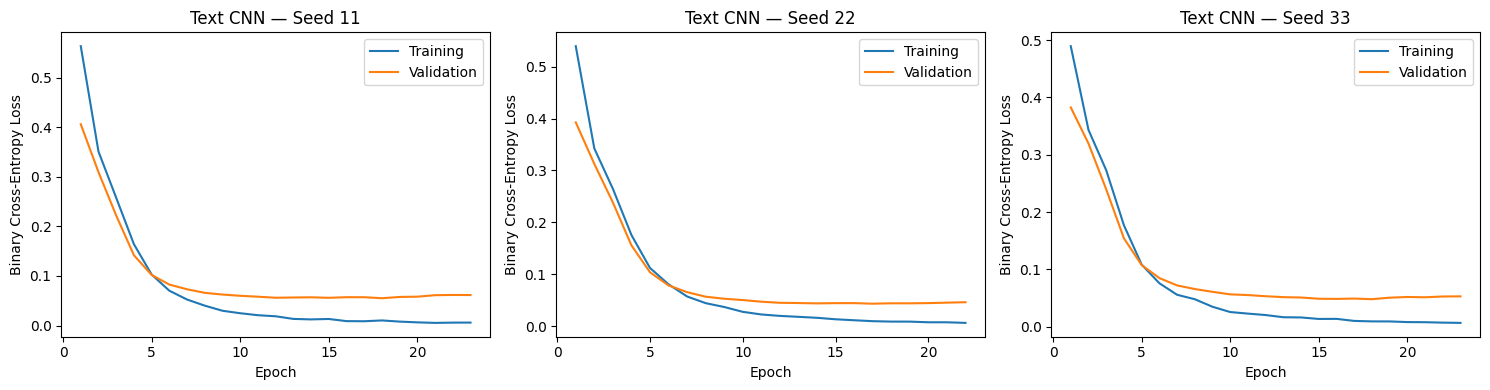

accuracy           precision_spam           recall_spam  \
                 mean       std           mean       std        mean   
model                                                                  
PyTorch MLP  0.981100  0.000744       0.966536  0.010616    0.880952   
Text CNN     0.987113  0.002232       0.968078  0.000582    0.928571   

                        f1_spam            
                  std      mean       std  
model                                      
PyTorch MLP  0.005891  0.921717  0.002644  
Text CNN     0.017674  0.947860  0.009442

Selected using validation results: Text CNN


In [ ]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4)
)

for axis, seed in zip(axes, CNN_SEEDS):
    history_frame = cnn_histories[seed]

    axis.plot(
        history_frame["epoch"],
        history_frame["train_loss"],
        label="Training"
    )

    axis.plot(
        history_frame["epoch"],
        history_frame["validation_loss"],
        label="Validation"
    )

    axis.set_title(f"Text CNN — Seed {seed}")
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Binary Cross-Entropy Loss")
    axis.legend()

plt.tight_layout()

plt.savefig(
    output_dir / "text_cnn_learning_curves.png",
    dpi=200
)

plt.show()

neural_validation_results = pd.concat(
    [
        mlp_results_df,
        cnn_results_df
    ],
    ignore_index=True
)

validation_comparison = (
    neural_validation_results
    .groupby("model")[
        [
            "accuracy",
            "precision_spam",
            "recall_spam",
            "f1_spam"
        ]
    ]
    .agg(["mean", "std"])
)

validation_comparison.to_csv(
    output_dir / "neural_validation_comparison.csv"
)

display(validation_comparison)

selected_architecture = (
    neural_validation_results
    .groupby("model")["f1_spam"]
    .mean()
    .idxmax()
)

with open(
    output_dir / "selected_architecture.json",
    "w"
) as file:
    json.dump(
        {
            "selected_architecture": selected_architecture,
            "selection_metric": "Mean validation Spam F1",
            "threshold": 0.5,
            "seeds": CNN_SEEDS,
            "representative_seed": 11,
            "test_used_for_selection": False
        },
        file,
        indent=4
    )

print(
    "Selected using validation results:",
    selected_architecture
)

# Step 6: Evaluate the effect of removing dropout from the Text CNN

## Define the CNN dropout ablation

In [ ]:
CNN_ABLATION_CONFIG = {
    **CNN_CONFIG,
    "dropout": 0.0
}

with open(
    output_dir / "cnn_ablation_config.json",
    "w"
) as file:
    json.dump(
        {
            "configuration": CNN_ABLATION_CONFIG,
            "seeds": CNN_SEEDS,
            "changed_factor": "Dropout: 0.3 to 0.0",
            "evaluation_set": "validation"
        },
        file,
        indent=4
    )


def train_cnn_ablation(seed):
    set_seed(seed)

    config = CNN_ABLATION_CONFIG

    model = SpamTextCNN(
        vocabulary_size=cnn_vocabulary_size,
        embedding_dimension=config["embedding_dimension"],
        filters=config["filters"],
        kernel_size=config["kernel_size"],
        dropout=config["dropout"]
    ).to(device)

    generator = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(
        cnn_train_dataset,
        batch_size=config["batch_size"],
        shuffle=True,
        generator=generator
    )

    validation_loader = DataLoader(
        cnn_validation_dataset,
        batch_size=config["batch_size"],
        shuffle=False
    )

    criterion = nn.BCEWithLogitsLoss()

    optimiser = torch.optim.Adam(
        model.parameters(),
        lr=config["learning_rate"],
        weight_decay=config["weight_decay"]
    )

    checkpoint_path = (
        output_dir / f"text_cnn_no_dropout_seed_{seed}.pt"
    )

    best_loss = float("inf")
    best_state = None
    best_epoch = 0
    patience_count = 0
    history = []

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    for epoch in range(config["max_epochs"]):
        model.train()
        train_loss_sum = 0.0

        for features, targets in train_loader:
            features = features.to(device)
            targets = targets.to(device)

            optimiser.zero_grad()

            loss = criterion(
                model(features),
                targets
            )

            loss.backward()
            optimiser.step()

            train_loss_sum += loss.item() * len(targets)

        train_loss = (
            train_loss_sum / len(cnn_train_dataset)
        )

        model.eval()
        validation_loss_sum = 0.0

        with torch.no_grad():
            for features, targets in validation_loader:
                features = features.to(device)
                targets = targets.to(device)

                loss = criterion(
                    model(features),
                    targets
                )

                validation_loss_sum += (
                    loss.item() * len(targets)
                )

        validation_loss = (
            validation_loss_sum
            / len(cnn_validation_dataset)
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "validation_loss": validation_loss
        })

        print(
            f"Seed {seed} | Epoch {epoch + 1:02d} | "
            f"Train: {train_loss:.4f} | "
            f"Validation: {validation_loss:.4f}"
        )

        if (
            validation_loss
            < best_loss - config["min_delta"]
        ):
            best_loss = validation_loss
            best_epoch = epoch + 1
            patience_count = 0

            best_state = {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            }

            torch.save(best_state, checkpoint_path)

        else:
            patience_count += 1

        if patience_count >= config["patience"]:
            print("Early stopping.")
            break

    if device.type == "cuda":
        torch.cuda.synchronize()

    training_seconds = time.perf_counter() - start_time

    model.load_state_dict(best_state)
    model.eval()

    probabilities = []

    with torch.no_grad():
        for features, _ in validation_loader:
            probabilities.extend(
                torch.sigmoid(
                    model(features.to(device))
                ).cpu().numpy().tolist()
            )

    predictions = (
        np.asarray(probabilities) >= config["threshold"]
    ).astype(int)

    targets = y_val_cnn.numpy().astype(int)

    result = {
        "model": "Text CNN without dropout",
        "seed": seed,
        "dropout": config["dropout"],
        "evaluation_set": "validation",
        "accuracy": float(
            accuracy_score(targets, predictions)
        ),
        "precision_spam": float(
            precision_score(
                targets, predictions, zero_division=0
            )
        ),
        "recall_spam": float(
            recall_score(
                targets, predictions, zero_division=0
            )
        ),
        "f1_spam": float(
            f1_score(
                targets, predictions, zero_division=0
            )
        ),
        "best_epoch": best_epoch,
        "actual_epochs": len(history),
        "best_validation_loss": best_loss,
        "training_seconds": training_seconds,
        "checkpoint": checkpoint_path.name
    }

    history_df = pd.DataFrame(history)

    history_df.to_csv(
        output_dir / f"cnn_ablation_history_{seed}.csv",
        index=False
    )

    with open(
        output_dir / f"cnn_ablation_run_{seed}.json",
        "w"
    ) as file:
        json.dump(
            {
                "configuration": config,
                "result": result
            },
            file,
            indent=4
        )

    return result, history_df

## Run and compare the ablation

In [ ]:
cnn_ablation_results = []
cnn_ablation_histories = {}

for seed in CNN_SEEDS:
    print(f"\nTraining CNN without dropout — seed {seed}")

    result, history_df = train_cnn_ablation(seed)

    cnn_ablation_results.append(result)
    cnn_ablation_histories[seed] = history_df

cnn_ablation_df = pd.DataFrame(cnn_ablation_results)

cnn_ablation_df.to_csv(
    output_dir / "cnn_ablation_validation_results.csv",
    index=False
)

original = cnn_results_df.copy()
original["variant"] = "Dropout 0.3"

ablated = cnn_ablation_df.copy()
ablated["variant"] = "Dropout 0.0"

ablation_combined = pd.concat(
    [original, ablated],
    ignore_index=True
)

ablation_summary = (
    ablation_combined
    .groupby("variant")[
        [
            "accuracy",
            "precision_spam",
            "recall_spam",
            "f1_spam"
        ]
    ]
    .agg(["mean", "std"])
)

ablation_summary.to_csv(
    output_dir / "cnn_ablation_summary.csv"
)

display(ablation_summary)

paired_ablation = original[
    ["seed", "f1_spam", "actual_epochs"]
].merge(
    ablated[["seed", "f1_spam", "actual_epochs"]],
    on="seed",
    suffixes=("_original", "_no_dropout"),
    validate="one_to_one"
)

paired_ablation["f1_change"] = (
    paired_ablation["f1_spam_no_dropout"]
    - paired_ablation["f1_spam_original"]
)

paired_ablation.to_csv(
    output_dir / "cnn_ablation_paired.csv",
    index=False
)

display(paired_ablation)

print(
    "Mean F1 change after removing dropout:",
    paired_ablation["f1_change"].mean()
)


Training CNN without dropout — seed 11
Seed 11 | Epoch 01 | Train: 0.5534 | Validation: 0.3947
Seed 11 | Epoch 02 | Train: 0.3285 | Validation: 0.2932
Seed 11 | Epoch 03 | Train: 0.2223 | Validation: 0.1931
Seed 11 | Epoch 04 | Train: 0.1255 | Validation: 0.1223
Seed 11 | Epoch 05 | Train: 0.0742 | Validation: 0.0912
Seed 11 | Epoch 06 | Train: 0.0495 | Validation: 0.0766
Seed 11 | Epoch 07 | Train: 0.0354 | Validation: 0.0695
Seed 11 | Epoch 08 | Train: 0.0264 | Validation: 0.0645
Seed 11 | Epoch 09 | Train: 0.0199 | Validation: 0.0618
Seed 11 | Epoch 10 | Train: 0.0152 | Validation: 0.0598
Seed 11 | Epoch 11 | Train: 0.0117 | Validation: 0.0595
Seed 11 | Epoch 12 | Train: 0.0093 | Validation: 0.0589
Seed 11 | Epoch 13 | Train: 0.0075 | Validation: 0.0591
Seed 11 | Epoch 14 | Train: 0.0063 | Validation: 0.0597
Seed 11 | Epoch 15 | Train: 0.0054 | Validation: 0.0599
Seed 11 | Epoch 16 | Train: 0.0047 | Validation: 0.0611
Seed 11 | Epoch 17 | Train: 0.0041 | Validation: 0.0615
Early st

accuracy           precision_spam           recall_spam  \
                 mean       std           mean       std        mean   
variant                                                                
Dropout 0.0  0.986254  0.002976       0.967854  0.010646    0.921769   
Dropout 0.3  0.987113  0.002232       0.968078  0.000582    0.928571   

                        f1_spam            
                  std      mean       std  
variant                                    
Dropout 0.0  0.015587  0.944225  0.012222  
Dropout 0.3  0.017674  0.947860  0.009442

,seed,f1_spam_original,actual_epochs_original,f1_spam_no_dropout,actual_epochs_no_dropout,f1_change
0,11,0.942408,23,0.937500,17,-0.004908
1,22,0.958763,22,0.958333,19,-0.000430
2,33,0.942408,23,0.936842,21,-0.005566


Mean F1 change after removing dropout: -0.0036347339760494832


## Plot the paired ablation results

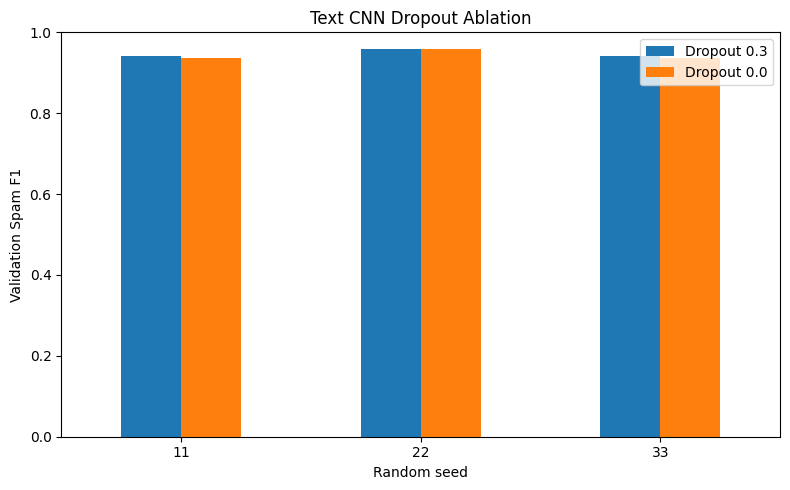

In [ ]:
plot_data = paired_ablation.set_index("seed")[
    ["f1_spam_original", "f1_spam_no_dropout"]
].rename(
    columns={
        "f1_spam_original": "Dropout 0.3",
        "f1_spam_no_dropout": "Dropout 0.0"
    }
)

axis = plot_data.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

axis.set_xlabel("Random seed")
axis.set_ylabel("Validation Spam F1")
axis.set_title("Text CNN Dropout Ablation")
axis.set_ylim(0, 1)

plt.tight_layout()

plt.savefig(
    output_dir / "cnn_dropout_ablation.png",
    dpi=200
)

plt.show()

# Step 7: Evaluate the frozen baseline, MLP and Text CNN on the test set

##freeze settings and prepare test inputs

In [ ]:
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay
)

FINAL_SEEDS = [11, 22, 33]
REPRESENTATIVE_SEED = 11

assert CNN_CONFIG["dropout"] == 0.3
assert MLP_CONFIG["dropout"] == 0.3

required_files = [
    output_dir / "logistic_regression_baseline.joblib"
]

required_files += [
    output_dir / f"pytorch_mlp_seed_{seed}.pt"
    for seed in FINAL_SEEDS
]

required_files += [
    output_dir / f"text_cnn_seed_{seed}.pt"
    for seed in FINAL_SEEDS
]

for path in required_files:
    assert path.exists(), f"Missing saved model: {path.name}"

final_protocol = {
    "selected_architecture": "Text CNN",
    "cnn_dropout": 0.3,
    "threshold": 0.5,
    "seeds": FINAL_SEEDS,
    "representative_seed_for_plots": REPRESENTATIVE_SEED,
    "selection_basis": "Mean validation Spam F1",
    "test_used_for_selection": False,
    "stress_test": {
        "type": "Delete 10% of non-whitespace characters",
        "random_seed": 2026,
        "evaluation_set": "Entire fixed test set",
        "retraining": False
    }
}

with open(
    output_dir / "final_evaluation_protocol.json",
    "w"
) as file:
    json.dump(final_protocol, file, indent=4)

X_test_mlp = torch.from_numpy(
    dense_float32(X_test_tfidf)
)

X_test_cnn = torch.from_numpy(
    encode_sms_messages(X_test)
)

y_test_array = np.asarray(
    y_test,
    dtype=np.int64
).reshape(-1)

assert len(X_test_mlp) == len(y_test_array)
assert len(X_test_cnn) == len(y_test_array)

print("Test samples:", len(y_test_array))
print("Original CNN dropout:", CNN_CONFIG["dropout"])
print("Final configurations frozen.")

Test samples: 776
Original CNN dropout: 0.3
Final configurations frozen.


##Evaluate all saved final models

In [ ]:
def predict_neural_probabilities(
    model,
    input_tensor,
    batch_size=64
):
    model.eval()
    probabilities = []

    with torch.no_grad():
        for start in range(
            0,
            len(input_tensor),
            batch_size
        ):
            features = input_tensor[
                start:start + batch_size
            ].to(device)

            logits = model(features)

            probabilities.extend(
                torch.sigmoid(logits)
                .cpu()
                .numpy()
                .tolist()
            )

    return np.asarray(probabilities)


def calculate_test_metrics(targets, probabilities):
    predictions = (
        np.asarray(probabilities) >= 0.5
    ).astype(int)

    return {
        "accuracy": float(
            accuracy_score(targets, predictions)
        ),
        "precision_spam": float(
            precision_score(
                targets,
                predictions,
                zero_division=0
            )
        ),
        "recall_spam": float(
            recall_score(
                targets,
                predictions,
                zero_division=0
            )
        ),
        "f1_spam": float(
            f1_score(
                targets,
                predictions,
                zero_division=0
            )
        ),
        "average_precision": float(
            average_precision_score(
                targets,
                probabilities
            )
        )
    }


baseline_model = joblib.load(
    output_dir / "logistic_regression_baseline.joblib"
)

baseline_spam_column = int(
    np.flatnonzero(
        baseline_model.classes_ == 1
    )[0]
)

baseline_test_probabilities = (
    baseline_model.predict_proba(
        X_test_tfidf
    )[:, baseline_spam_column]
)

test_probabilities = {
    ("Logistic Regression", 42):
        baseline_test_probabilities
}

test_rows = [
    {
        "model": "Logistic Regression",
        "evaluation_set": "test",
        "seed": 42,
        "checkpoint": "logistic_regression_baseline.joblib",
        **calculate_test_metrics(
            y_test_array,
            baseline_test_probabilities
        )
    }
]

for seed in FINAL_SEEDS:
    mlp = SpamMLP(
        input_size=X_train_mlp.shape[1],
        hidden_sizes=MLP_CONFIG["hidden_sizes"],
        dropout=MLP_CONFIG["dropout"]
    ).to(device)

    mlp_checkpoint = (
        output_dir / f"pytorch_mlp_seed_{seed}.pt"
    )

    mlp.load_state_dict(
        torch.load(
            mlp_checkpoint,
            map_location=device,
            weights_only=True
        )
    )

    mlp_probabilities = (
        predict_neural_probabilities(
            mlp,
            X_test_mlp,
            MLP_CONFIG["batch_size"]
        )
    )

    test_probabilities[
        ("PyTorch MLP", seed)
    ] = mlp_probabilities

    test_rows.append({
        "model": "PyTorch MLP",
        "evaluation_set": "test",
        "seed": seed,
        "checkpoint": mlp_checkpoint.name,
        **calculate_test_metrics(
            y_test_array,
            mlp_probabilities
        )
    })

    cnn = create_text_cnn().to(device)

    cnn_checkpoint = (
        output_dir / f"text_cnn_seed_{seed}.pt"
    )

    cnn.load_state_dict(
        torch.load(
            cnn_checkpoint,
            map_location=device,
            weights_only=True
        )
    )

    cnn_probabilities = (
        predict_neural_probabilities(
            cnn,
            X_test_cnn,
            CNN_CONFIG["batch_size"]
        )
    )

    test_probabilities[
        ("Text CNN", seed)
    ] = cnn_probabilities

    test_rows.append({
        "model": "Text CNN",
        "evaluation_set": "test",
        "seed": seed,
        "checkpoint": cnn_checkpoint.name,
        **calculate_test_metrics(
            y_test_array,
            cnn_probabilities
        )
    })

test_results_df = pd.DataFrame(test_rows)

test_results_df.to_csv(
    output_dir / "final_test_results.csv",
    index=False
)

display(test_results_df)

test_summary = (
    test_results_df.groupby("model")[
        [
            "accuracy",
            "precision_spam",
            "recall_spam",
            "f1_spam",
            "average_precision"
        ]
    ]
    .agg(["mean", "std"])
)

test_summary.to_csv(
    output_dir / "final_test_summary.csv"
)

print("Test mean and sample standard deviation:")
display(test_summary)

print(
    "Baseline standard deviation is undefined "
    "because it has one run."
)

,model,evaluation_set,seed,checkpoint,accuracy,precision_spam,recall_spam,f1_spam,average_precision
0,Logistic Regression,test,42,logistic_regression_baseline.joblib,0.965206,1.000000,0.724490,0.840237,0.953227
1,PyTorch MLP,test,11,pytorch_mlp_seed_11.pt,0.980670,0.946237,0.897959,0.921466,0.965564
2,Text CNN,test,11,text_cnn_seed_11.pt,0.979381,0.927083,0.908163,0.917526,0.974777
3,PyTorch MLP,test,22,pytorch_mlp_seed_22.pt,0.975515,0.915789,0.887755,0.901554,0.963683
4,Text CNN,test,22,text_cnn_seed_22.pt,0.983247,0.929293,0.938776,0.934010,0.981559
5,PyTorch MLP,test,33,pytorch_mlp_seed_33.pt,0.983247,0.956989,0.908163,0.931937,0.965396
6,Text CNN,test,33,text_cnn_seed_33.pt,0.975515,0.883495,0.928571,0.905473,0.981069


Test mean and sample standard deviation:


accuracy           precision_spam           recall_spam  \
                         mean       std           mean       std        mean   
model                                                                          
Logistic Regression  0.965206       NaN       1.000000       NaN    0.724490   
PyTorch MLP          0.979811  0.003937       0.939672  0.021370    0.897959   
Text CNN             0.979381  0.003866       0.913290  0.025827    0.925170   

                                f1_spam           average_precision            
                          std      mean       std              mean       std  
model                                                                          
Logistic Regression       NaN  0.840237       NaN          0.953227       NaN  
PyTorch MLP          0.010204  0.918319  0.015434          0.964881  0.001041  
Text CNN             0.015587  0.919003  0.014326          0.979135  0.003782

Baseline standard deviation is undefined because it has one run.


##Save a traceable validation-test comparison

In [ ]:
with open(
    output_dir / "baseline_validation_metrics.json",
    "r"
) as file:
    saved_baseline_validation = json.load(file)

validation_links = [
    {
        "model": "Logistic Regression",
        "seed": 42,
        "validation_f1_spam":
            saved_baseline_validation["f1_spam"],
        "configuration": "Baseline training cell and experiment_settings.json"
    }
]

for _, row in mlp_results_df.iterrows():
    seed = int(row["seed"])

    validation_links.append({
        "model": "PyTorch MLP",
        "seed": seed,
        "validation_f1_spam": float(row["f1_spam"]),
        "configuration": f"pytorch_mlp_run_{seed}.json"
    })

for _, row in cnn_results_df.iterrows():
    seed = int(row["seed"])

    validation_links.append({
        "model": "Text CNN",
        "seed": seed,
        "validation_f1_spam": float(row["f1_spam"]),
        "configuration": f"text_cnn_run_{seed}.json"
    })

traceable_results = test_results_df.rename(
    columns={"f1_spam": "test_f1_spam"}
).merge(
    pd.DataFrame(validation_links),
    on=["model", "seed"],
    validate="one_to_one"
)

traceable_results.to_csv(
    output_dir / "model_results_traceability.csv",
    index=False
)

display(
    traceable_results[
        [
            "model",
            "seed",
            "configuration",
            "checkpoint",
            "validation_f1_spam",
            "test_f1_spam"
        ]
    ]
)

,model,seed,configuration,checkpoint,validation_f1_spam,test_f1_spam
0,Logistic Regression,42,Baseline training cell and experiment_settings...,logistic_regression_baseline.joblib,0.812121,0.840237
1,PyTorch MLP,11,pytorch_mlp_run_11.json,pytorch_mlp_seed_11.pt,0.924731,0.921466
2,Text CNN,11,text_cnn_run_11.json,text_cnn_seed_11.pt,0.942408,0.917526
3,PyTorch MLP,22,pytorch_mlp_run_22.json,pytorch_mlp_seed_22.pt,0.920635,0.901554
4,Text CNN,22,text_cnn_run_22.json,text_cnn_seed_22.pt,0.958763,0.934010
5,PyTorch MLP,33,pytorch_mlp_run_33.json,pytorch_mlp_seed_33.pt,0.919786,0.931937
6,Text CNN,33,text_cnn_run_33.json,text_cnn_seed_33.pt,0.942408,0.905473


## Save class-level reports and evaluation plots


Logistic Regression — Test classification report
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       678
        Spam       1.00      0.72      0.84        98

    accuracy                           0.97       776
   macro avg       0.98      0.86      0.91       776
weighted avg       0.97      0.97      0.96       776



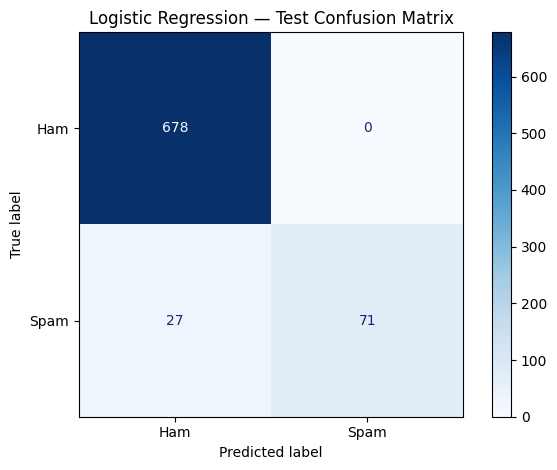


PyTorch MLP — Test classification report
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       678
        Spam       0.95      0.90      0.92        98

    accuracy                           0.98       776
   macro avg       0.97      0.95      0.96       776
weighted avg       0.98      0.98      0.98       776



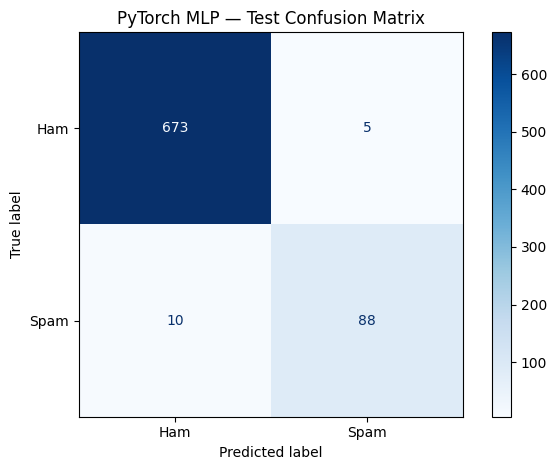


Text CNN — Test classification report
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       678
        Spam       0.93      0.91      0.92        98

    accuracy                           0.98       776
   macro avg       0.96      0.95      0.95       776
weighted avg       0.98      0.98      0.98       776



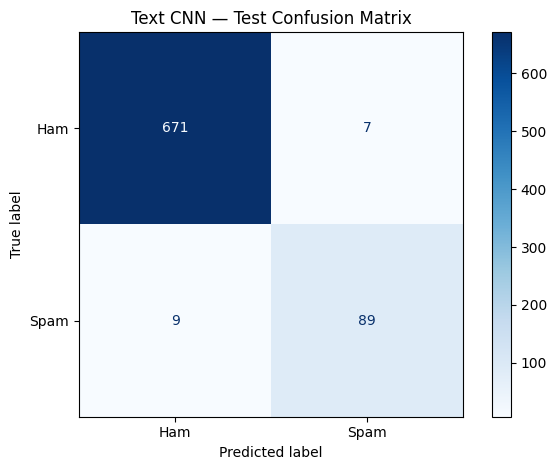

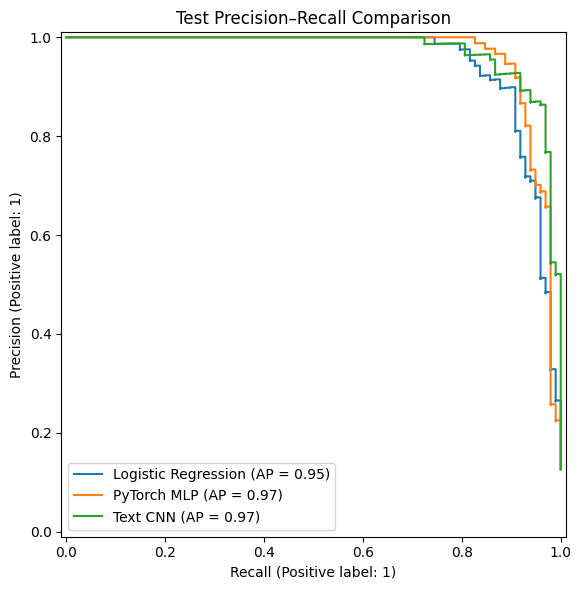

In [ ]:
plot_models = [
    ("Logistic Regression", 42, "baseline"),
    ("PyTorch MLP", REPRESENTATIVE_SEED, "mlp"),
    ("Text CNN", REPRESENTATIVE_SEED, "cnn")
]

for model_name, seed, filename in plot_models:
    probabilities = test_probabilities[
        (model_name, seed)
    ]

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    print(f"\n{model_name} — Test classification report")

    print(
        classification_report(
            y_test_array,
            predictions,
            labels=[0, 1],
            target_names=["Ham", "Spam"],
            zero_division=0
        )
    )

    report = classification_report(
        y_test_array,
        predictions,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        output_dict=True,
        zero_division=0
    )

    with open(
        output_dir / f"{filename}_test_class_report.json",
        "w"
    ) as file:
        json.dump(report, file, indent=4)

    ConfusionMatrixDisplay.from_predictions(
        y_test_array,
        predictions,
        labels=[0, 1],
        display_labels=["Ham", "Spam"],
        cmap="Blues"
    )

    plt.title(
        f"{model_name} — Test Confusion Matrix"
    )
    plt.tight_layout()

    plt.savefig(
        output_dir / f"{filename}_test_confusion.png",
        dpi=200
    )
    plt.show()

fig, axis = plt.subplots(figsize=(8, 6))

for model_name, seed, filename in plot_models:
    PrecisionRecallDisplay.from_predictions(
        y_test_array,
        test_probabilities[(model_name, seed)],
        name=model_name,
        ax=axis
    )

axis.set_title("Test Precision–Recall Comparison")
plt.tight_layout()

plt.savefig(
    output_dir / "test_precision_recall_comparison.png",
    dpi=200
)

plt.show()

# Step 8: Analyse prediction errors and test robustness to text corruption

##Inspect representative CNN prediction errors

In [ ]:
cnn_test_probabilities = test_probabilities[
    ("Text CNN", REPRESENTATIVE_SEED)
]

cnn_test_predictions = (
    cnn_test_probabilities >= 0.5
).astype(int)

error_analysis = pd.DataFrame({
    "test_position": np.arange(len(y_test_array)),
    "message": list(X_test),
    "actual": y_test_array,
    "predicted": cnn_test_predictions,
    "spam_score": cnn_test_probabilities
})

error_analysis["error_type"] = np.select(
    [
        (
            (error_analysis["actual"] == 0)
            & (error_analysis["predicted"] == 1)
        ),
        (
            (error_analysis["actual"] == 1)
            & (error_analysis["predicted"] == 0)
        )
    ],
    [
        "False positive: Ham predicted as Spam",
        "False negative: Spam predicted as Ham"
    ],
    default="Correct"
)

errors = error_analysis.loc[
    error_analysis["actual"]
    != error_analysis["predicted"]
].copy()

false_positives = errors.loc[
    errors["actual"] == 0
].sort_values("test_position")

false_negatives = errors.loc[
    errors["actual"] == 1
].sort_values("test_position")

representative_errors = pd.concat([
    false_positives.head(3),
    false_negatives.head(3)
])

if len(representative_errors) < min(5, len(errors)):
    remaining = errors.loc[
        ~errors["test_position"].isin(
            representative_errors["test_position"]
        )
    ]

    needed = min(5, len(errors)) - len(
        representative_errors
    )

    representative_errors = pd.concat([
        representative_errors,
        remaining.head(needed)
    ])

representative_errors = (
    representative_errors
    .sort_values("test_position")
    .reset_index(drop=True)
)

representative_errors["possible_reason"] = ""
representative_errors["practical_effect"] = ""

errors.to_csv(
    output_dir / "cnn_all_test_errors.csv",
    index=False
)

representative_errors.to_csv(
    output_dir / "cnn_representative_errors.csv",
    index=False
)

print("Test samples:", len(y_test_array))
print("Total errors:", len(errors))
print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))

for number, row in representative_errors.iterrows():
    print(f"\nExample {number + 1}")
    print("Error:", row["error_type"])
    print("Spam score:", round(row["spam_score"], 4))
    print("Message:", row["message"])

Test samples: 776
Total errors: 16
False positives: 7
False negatives: 9

Example 1
Error: False negative: Spam predicted as Ham
Spam score: 0.1999
Message: Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo

Example 2
Error: False positive: Ham predicted as Spam
Spam score: 0.6467
Message: K k:) sms chat with me.

Example 3
Error: False negative: Spam predicted as Ham
Spam score: 0.3008
Message: ringtoneking 84484

Example 4
Error: False negative: Spam predicted as Ham
Spam score: 0.0143
Message: Latest News! Police station toilet stolen, cops have nothing to go on!

Example 5
Error: False positive: Ham predicted as Spam
Spam score: 0.9729
Message: Glad to see your reply.

Example 6
Error: False positive: Ham predicted as Spam
Spam score: 0.7384
Message: Your daily text from me – a favour this time


##Create the predefined corrupted test set


In [ ]:
noise_rng = np.random.default_rng(2026)


def delete_characters(message, fraction=0.10):
    positions = [
        index
        for index, character in enumerate(message)
        if not character.isspace()
    ]

    number_to_delete = int(
        round(fraction * len(positions))
    )

    if number_to_delete == 0:
        return message

    deleted_positions = set(
        noise_rng.choice(
            positions,
            size=number_to_delete,
            replace=False
        ).tolist()
    )

    return "".join(
        character
        for index, character in enumerate(message)
        if index not in deleted_positions
    )


original_test_messages = list(X_test)

corrupted_test_messages = [
    delete_characters(message)
    for message in original_test_messages
]

changed_messages = sum(
    original != corrupted
    for original, corrupted in zip(
        original_test_messages,
        corrupted_test_messages
    )
)

stress_protocol = {
    "corruption": "Random non-whitespace character deletion",
    "fraction": 0.10,
    "rounding": "round(fraction * eligible characters)",
    "random_seed": 2026,
    "samples": len(corrupted_test_messages),
    "changed_messages": changed_messages,
    "same_corruption_for_all_models": True,
    "retraining": False,
    "threshold": 0.5
}

with open(
    output_dir / "stress_test_protocol.json",
    "w"
) as file:
    json.dump(stress_protocol, file, indent=4)

print(json.dumps(stress_protocol, indent=4))

for index in range(3):
    print("\nOriginal:", original_test_messages[index])
    print("Corrupted:", corrupted_test_messages[index])

{
    "corruption": "Random non-whitespace character deletion",
    "fraction": 0.1,
    "rounding": "round(fraction * eligible characters)",
    "random_seed": 2026,
    "samples": 776,
    "changed_messages": 775,
    "same_corruption_for_all_models": true,
    "retraining": false,
    "threshold": 0.5
}

Original: SMS. ac sun0819 posts HELLO:"You seem cool, wanted to say hi. HI!!!" Stop? Send STOP to 62468
Corrupted: SS. ac un081 posts HELLO:"Yo eem coo, wanted to sy hi. HI!!!" Stp? Send STOP to 62468

Original: Are you not around or just still asleep? :V
Corrupted: Are o not around or just sill aseep? :V

Original: I'm going out to buy mum's present ar.
Corrupted: I'm going ut to buy mum's resen ar.


##Evaluate robustness using the saved models

In [ ]:
corrupted_tfidf = tfidf.transform(
    corrupted_test_messages
)

corrupted_mlp_inputs = torch.from_numpy(
    dense_float32(corrupted_tfidf)
)

corrupted_cnn_inputs = torch.from_numpy(
    encode_sms_messages(corrupted_test_messages)
)

baseline_corrupted_probabilities = (
    baseline_model.predict_proba(
        corrupted_tfidf
    )[:, baseline_spam_column]
)

stress_rows = [{
    "model": "Logistic Regression",
    "seed": 42,
    "samples": len(y_test_array),
    **calculate_test_metrics(
        y_test_array,
        baseline_corrupted_probabilities
    )
}]

for seed in FINAL_SEEDS:
    mlp = SpamMLP(
        input_size=X_train_mlp.shape[1],
        hidden_sizes=MLP_CONFIG["hidden_sizes"],
        dropout=MLP_CONFIG["dropout"]
    ).to(device)

    mlp.load_state_dict(
        torch.load(
            output_dir / f"pytorch_mlp_seed_{seed}.pt",
            map_location=device,
            weights_only=True
        )
    )

    probabilities = predict_neural_probabilities(
        mlp,
        corrupted_mlp_inputs,
        MLP_CONFIG["batch_size"]
    )

    stress_rows.append({
        "model": "PyTorch MLP",
        "seed": seed,
        "samples": len(y_test_array),
        **calculate_test_metrics(
            y_test_array,
            probabilities
        )
    })

    cnn = create_text_cnn().to(device)

    cnn.load_state_dict(
        torch.load(
            output_dir / f"text_cnn_seed_{seed}.pt",
            map_location=device,
            weights_only=True
        )
    )

    probabilities = predict_neural_probabilities(
        cnn,
        corrupted_cnn_inputs,
        CNN_CONFIG["batch_size"]
    )

    stress_rows.append({
        "model": "Text CNN",
        "seed": seed,
        "samples": len(y_test_array),
        **calculate_test_metrics(
            y_test_array,
            probabilities
        )
    })

stress_results_df = pd.DataFrame(stress_rows)

stress_results_df.to_csv(
    output_dir / "stress_test_results.csv",
    index=False
)

display(stress_results_df)

,model,seed,samples,accuracy,precision_spam,recall_spam,f1_spam,average_precision
0,Logistic Regression,42,776,0.932990,0.979167,0.479592,0.643836,0.921202
1,PyTorch MLP,11,776,0.976804,0.954545,0.857143,0.903226,0.940597
2,Text CNN,11,776,0.971649,0.913043,0.857143,0.884211,0.949739
3,PyTorch MLP,22,776,0.972938,0.923077,0.857143,0.888889,0.931819
4,Text CNN,22,776,0.967784,0.892473,0.846939,0.869110,0.949429
5,PyTorch MLP,33,776,0.974227,0.943182,0.846939,0.892473,0.938748
6,Text CNN,33,776,0.966495,0.882979,0.846939,0.864583,0.956357


## Compare clean and corrupted performance

,model,seed,f1_spam_clean,recall_spam_clean,f1_spam_corrupted,recall_spam_corrupted,f1_change,recall_change
0,Logistic Regression,42,0.840237,0.724490,0.643836,0.479592,-0.196401,-0.244898
1,PyTorch MLP,11,0.921466,0.897959,0.903226,0.857143,-0.018240,-0.040816
2,Text CNN,11,0.917526,0.908163,0.884211,0.857143,-0.033315,-0.051020
3,PyTorch MLP,22,0.901554,0.887755,0.888889,0.857143,-0.012666,-0.030612
4,Text CNN,22,0.934010,0.938776,0.869110,0.846939,-0.064900,-0.091837
5,PyTorch MLP,33,0.931937,0.908163,0.892473,0.846939,-0.039464,-0.061224
6,Text CNN,33,0.905473,0.928571,0.864583,0.846939,-0.040889,-0.081633


f1_spam_clean           f1_spam_corrupted            \
                             mean       std              mean       std   
model                                                                     
Logistic Regression      0.840237       NaN          0.643836       NaN   
PyTorch MLP              0.918319  0.015434          0.894863  0.007461   
Text CNN                 0.919003  0.014326          0.872635  0.010277   

                    f1_change          recall_change            
                         mean      std          mean       std  
model                                                           
Logistic Regression -0.196401      NaN     -0.244898       NaN  
PyTorch MLP         -0.023457  0.01414     -0.044218  0.015587  
Text CNN            -0.046368  0.01649     -0.074830  0.021241

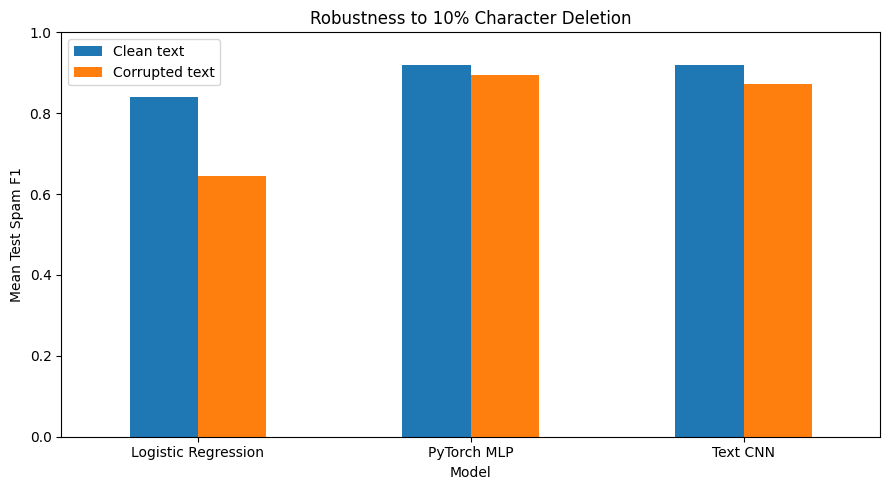

In [ ]:
stress_comparison = test_results_df[
    ["model", "seed", "f1_spam", "recall_spam"]
].merge(
    stress_results_df[
        ["model", "seed", "f1_spam", "recall_spam"]
    ],
    on=["model", "seed"],
    suffixes=("_clean", "_corrupted"),
    validate="one_to_one"
)

stress_comparison["f1_change"] = (
    stress_comparison["f1_spam_corrupted"]
    - stress_comparison["f1_spam_clean"]
)

stress_comparison["recall_change"] = (
    stress_comparison["recall_spam_corrupted"]
    - stress_comparison["recall_spam_clean"]
)

stress_comparison.to_csv(
    output_dir / "clean_corrupted_comparison.csv",
    index=False
)

display(stress_comparison)

stress_summary = (
    stress_comparison.groupby("model")[
        [
            "f1_spam_clean",
            "f1_spam_corrupted",
            "f1_change",
            "recall_change"
        ]
    ]
    .agg(["mean", "std"])
)

stress_summary.to_csv(
    output_dir / "stress_test_summary.csv"
)

display(stress_summary)

plot_data = (
    stress_comparison.groupby("model")[
        ["f1_spam_clean", "f1_spam_corrupted"]
    ]
    .mean()
    .rename(columns={
        "f1_spam_clean": "Clean text",
        "f1_spam_corrupted": "Corrupted text"
    })
)

axis = plot_data.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

axis.set_ylabel("Mean Test Spam F1")
axis.set_xlabel("Model")
axis.set_title("Robustness to 10% Character Deletion")
axis.set_ylim(0, 1)

plt.tight_layout()

plt.savefig(
    output_dir / "text_corruption_comparison.png",
    dpi=200
)

plt.show()

# Step 9: Measure inference cost and demonstrate saved-model predictions

##Load saved models for inference

In [ ]:
import time
import platform
import sklearn
import joblib

with open(
    output_dir / "pytorch_mlp_run_11.json"
) as file:
    saved_mlp_run = json.load(file)

with open(
    output_dir / "text_cnn_run_11.json"
) as file:
    saved_cnn_run = json.load(file)

with open(
    output_dir / "cnn_vocabulary.json",
    encoding="utf-8"
) as file:
    demo_vocabulary = json.load(file)

demo_mlp_config = saved_mlp_run["configuration"]
demo_cnn_config = saved_cnn_run["configuration"]

demo_vectorizer = joblib.load(
    output_dir / "tfidf_vectorizer.joblib"
)

demo_baseline = joblib.load(
    output_dir / "logistic_regression_baseline.joblib"
)

demo_mlp = SpamMLP(
    input_size=saved_mlp_run["input_size"],
    hidden_sizes=demo_mlp_config["hidden_sizes"],
    dropout=demo_mlp_config["dropout"]
).cpu()

demo_mlp.load_state_dict(
    torch.load(
        output_dir / "pytorch_mlp_seed_11.pt",
        map_location="cpu",
        weights_only=True
    )
)

demo_cnn = SpamTextCNN(
    vocabulary_size=saved_cnn_run["vocabulary_size"],
    embedding_dimension=demo_cnn_config[
        "embedding_dimension"
    ],
    filters=demo_cnn_config["filters"],
    kernel_size=demo_cnn_config["kernel_size"],
    dropout=demo_cnn_config["dropout"]
).cpu()

demo_cnn.load_state_dict(
    torch.load(
        output_dir / "text_cnn_seed_11.pt",
        map_location="cpu",
        weights_only=True
    )
)

demo_mlp.eval()
demo_cnn.eval()

demo_baseline_spam_column = int(
    np.flatnonzero(
        demo_baseline.classes_ == 1
    )[0]
)


def demo_encode(messages):
    sequences = np.zeros(
        (
            len(messages),
            demo_cnn_config["max_length"]
        ),
        dtype=np.int64
    )

    for index, message in enumerate(messages):
        tokens = re.findall(
            r"\w+|[^\w\s]",
            message.lower()
        )

        ids = [
            demo_vocabulary.get(token, 1)
            for token in tokens
        ][:demo_cnn_config["max_length"]]

        sequences[index, :len(ids)] = ids

    return torch.from_numpy(sequences)


def loaded_model_scores(messages, model_name):
    if model_name == "Logistic Regression":
        features = demo_vectorizer.transform(messages)

        return demo_baseline.predict_proba(
            features
        )[:, demo_baseline_spam_column]

    if model_name == "PyTorch MLP":
        features = demo_vectorizer.transform(
            messages
        ).toarray().astype(np.float32)

        with torch.inference_mode():
            return torch.sigmoid(
                demo_mlp(torch.from_numpy(features))
            ).numpy()

    if model_name == "Text CNN":
        features = demo_encode(messages)

        with torch.inference_mode():
            return torch.sigmoid(
                demo_cnn(features)
            ).numpy()

    raise ValueError("Unknown model name.")


print("Saved models and preprocessing loaded successfully.")

Saved models and preprocessing loaded successfully.


##Measure CPU inference latency


In [ ]:
previous_thread_count = torch.get_num_threads()
torch.set_num_threads(1)

benchmark_messages = [
    str(message)
    for message in list(X_val)[:20]
]

model_names = [
    "Logistic Regression",
    "PyTorch MLP",
    "Text CNN"
]

benchmark_rows = []

try:
    for model_name in model_names:
        for message in benchmark_messages:
            loaded_model_scores(
                [message],
                model_name
            )

        elapsed_times = []

        for repetition in range(5):
            for message in benchmark_messages:
                start = time.perf_counter()

                loaded_model_scores(
                    [message],
                    model_name
                )

                elapsed_times.append(
                    (
                        time.perf_counter() - start
                    ) * 1000
                )

        if model_name == "Logistic Regression":
            parameter_count = (
                demo_baseline.coef_.size
                + demo_baseline.intercept_.size
            )
            checkpoint_name = (
                "logistic_regression_baseline.joblib"
            )

        elif model_name == "PyTorch MLP":
            parameter_count = sum(
                parameter.numel()
                for parameter in demo_mlp.parameters()
                if parameter.requires_grad
            )
            checkpoint_name = "pytorch_mlp_seed_11.pt"

        else:
            parameter_count = sum(
                parameter.numel()
                for parameter in demo_cnn.parameters()
                if parameter.requires_grad
            )
            checkpoint_name = "text_cnn_seed_11.pt"

        benchmark_rows.append({
            "model": model_name,
            "parameters": int(parameter_count),
            "median_latency_ms": float(
                np.median(elapsed_times)
            ),
            "p95_latency_ms": float(
                np.percentile(elapsed_times, 95)
            ),
            "batch_size": 1,
            "device": "CPU",
            "torch_threads": 1,
            "timed_predictions": len(elapsed_times),
            "distinct_messages": len(benchmark_messages),
            "preprocessing_included": True,
            "model_loading_included": False,
            "checkpoint_size_kib": (
                output_dir / checkpoint_name
            ).stat().st_size / 1024
        })

finally:
    torch.set_num_threads(previous_thread_count)

inference_costs = pd.DataFrame(
    benchmark_rows
)

inference_costs.to_csv(
    output_dir / "inference_costs.csv",
    index=False
)

benchmark_environment = {
    "processor": platform.processor(),
    "machine": platform.machine(),
    "platform": platform.platform(),
    "pytorch": torch.__version__,
    "protocol": (
        "20 validation messages, batch size 1, "
        "one warm-up pass, five timed passes"
    )
}

with open(
    output_dir / "inference_benchmark_environment.json",
    "w"
) as file:
    json.dump(
        benchmark_environment,
        file,
        indent=4
    )

display(inference_costs)

,model,parameters,median_latency_ms,p95_latency_ms,batch_size,device,torch_threads,timed_predictions,distinct_messages,preprocessing_included,model_loading_included,checkpoint_size_kib
0,Logistic Regression,10001,0.802890,0.879392,1,CPU,1,100,20,True,False,78.967773
1,PyTorch MLP,642177,0.920893,1.043283,1,CPU,1,100,20,True,False,2511.473633
2,Text CNN,234561,0.293530,0.341733,1,CPU,1,100,20,True,False,918.933594


##Predict an unseen SMS using the saved CNN

In [ ]:
DEMO_MODEL = "Text CNN"


def classify_sms(message):
    if not isinstance(message, str):
        return {
            "status": "invalid",
            "reason": "Input must be text."
        }

    message = message.strip()

    if not message:
        return {
            "status": "invalid",
            "reason": "Please enter a non-empty SMS."
        }

    if len(message) > 2000:
        return {
            "status": "out_of_scope",
            "reason": (
                "The demo accepts at most "
                "2000 characters."
            )
        }

    letters = [
        character
        for character in message
        if character.isalpha()
    ]

    if letters:
        non_ascii_fraction = (
            sum(
                not character.isascii()
                for character in letters
            ) / len(letters)
        )

        if non_ascii_fraction > 0.2:
            return {
                "status": "out_of_scope",
                "reason": (
                    "This English-corpus model is not "
                    "validated for this script."
                )
            }

    encoded = demo_encode([message])

    recognised_tokens = (
        (encoded != 0) & (encoded != 1)
    ).sum().item()

    if recognised_tokens == 0:
        return {
            "status": "out_of_scope",
            "reason": (
                "No recognised vocabulary tokens."
            )
        }

    score = float(
        loaded_model_scores(
            [message],
            DEMO_MODEL
        )[0]
    )

    token_count = len(
        re.findall(
            r"\w+|[^\w\s]",
            message.lower()
        )
    )

    return {
        "status": "ok",
        "model": DEMO_MODEL,
        "seed": 11,
        "prediction": "Spam" if score >= 0.5 else "Ham",
        "spam_score": round(score, 4),
        "truncated": (
            token_count
            > demo_cnn_config["max_length"]
        ),
        "note": (
            "Model score is not a calibrated guarantee. "
            "Review important messages manually."
        )
    }


demo_examples = [
    "Can we meet at the library tomorrow afternoon?",
    "Congratulations! Claim your free prize by calling now!",
    "",
    "අද හවස හමුවෙමු"
]

demo_outputs = []

for message in demo_examples:
    result = classify_sms(message)

    demo_outputs.append({
        "input": message,
        "result": result
    })

    print("\nInput:", repr(message))
    print(json.dumps(result, indent=4))

with open(
    output_dir / "inference_demo_outputs.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        demo_outputs,
        file,
        indent=4,
        ensure_ascii=False
    )


Input: 'Can we meet at the library tomorrow afternoon?'
{
    "status": "ok",
    "model": "Text CNN",
    "seed": 11,
    "prediction": "Ham",
    "spam_score": 0.0012,
    "truncated": false,
    "note": "Model score is not a calibrated guarantee. Review important messages manually."
}

Input: 'Congratulations! Claim your free prize by calling now!'
{
    "status": "ok",
    "model": "Text CNN",
    "seed": 11,
    "prediction": "Spam",
    "spam_score": 0.9994,
    "truncated": false,
    "note": "Model score is not a calibrated guarantee. Review important messages manually."
}

Input: ''
{
    "status": "invalid",
    "reason": "Please enter a non-empty SMS."
}

Input: 'අද හවස හමුවෙමු'
{
    "status": "out_of_scope",
    "reason": "This English-corpus model is not validated for this script."
}


##Verify inference and accept a new message


In [ ]:
assert classify_sms("")["status"] == "invalid"
assert classify_sms(None)["status"] == "invalid"

normal_result = classify_sms(
    "Can we meet at the library tomorrow?"
)

assert normal_result["status"] == "ok"

assert (
    0.0 <= normal_result["spam_score"] <= 1.0
)

print("Inference smoke test passed.")

new_message = input("\nEnter an English SMS: ")

print(
    json.dumps(
        classify_sms(new_message),
        indent=4
    )
)

Inference smoke test passed.

Enter an English SMS: spam detected
{
    "status": "ok",
    "model": "Text CNN",
    "seed": 11,
    "prediction": "Ham",
    "spam_score": 0.2851,
    "truncated": false,
    "note": "Model score is not a calibrated guarantee. Review important messages manually."
}


##Save dependencies and back up project evidence

In [ ]:
from importlib.metadata import version
from zipfile import ZipFile, ZIP_DEFLATED
from pathlib import Path

dependency_names = [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "matplotlib",
    "seaborn",
    "joblib",
    "requests",
    "torch"
]

dependency_lines = [
    f"{name}=={version(name)}"
    for name in dependency_names
]

(output_dir / "requirements.txt").write_text(
    "\n".join(dependency_lines) + "\n",
    encoding="utf-8"
)

smoke_results = {
    "empty_input_rejected": (
        classify_sms("")["status"] == "invalid"
    ),
    "non_text_input_rejected": (
        classify_sms(None)["status"] == "invalid"
    ),
    "normal_input_processed": (
        normal_result["status"] == "ok"
    )
}

with open(
    output_dir / "inference_smoke_test.json",
    "w"
) as file:
    json.dump(smoke_results, file, indent=4)

backup_path = (
    output_dir.parent / "SMS_Project_Current_Backup.zip"
)

notebooks = (
    sorted(Path("/content").glob("*.ipynb"))
    if Path("/content").exists()
    else []
)

with ZipFile(
    backup_path,
    "w",
    compression=ZIP_DEFLATED
) as archive:
    for path in sorted(output_dir.rglob("*")):
        if path.is_file() and path.resolve() != backup_path.resolve():
            archive.write(
                path,
                arcname=str(
                    Path("sms_spam_project")
                    / path.relative_to(output_dir)
                )
            )

    for notebook in notebooks:
        archive.write(
            notebook,
            arcname=str(
                Path("notebooks") / notebook.name
            )
        )

print("Backup created:", backup_path)
print("Notebooks included:", len(notebooks))

if not notebooks:
    print(
        "Download your Colab notebook and add it "
        "to the final submission package."
    )

print(
    "This is a working backup. "
    "Final README, reports and demonstration "
    "must still be added."
)

from google.colab import files

files.download(str(backup_path))

Backup created: /content/SMS_Project_Current_Backup.zip
Notebooks included: 0
Download your Colab notebook and add it to the final submission package.
This is a working backup. Final README, reports and demonstration must still be added.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Step 11: Complete error analysis and prepare the reproduction package

##Update dataset metadata using actual counts

In [ ]:


import json
from pathlib import Path

output_dir = Path(output_dir)

settings_path = output_dir / "experiment_settings.json"

with open(settings_path, "r") as file:
    settings = json.load(file)

settings["original_rows"] = int(len(df))
settings["cleaned_rows"] = int(len(data))

settings["duplicates_removed"] = int(
    df[["label", "message"]].duplicated().sum()
)

settings["split_sizes"] = {
    "train": int(len(X_train)),
    "validation": int(len(X_val)),
    "test": int(len(X_test))
}

with open(settings_path, "w") as file:
    json.dump(settings, file, indent=4)

print(json.dumps(settings, indent=4))

##Audit message overlap between saved splits

In [ ]:


def normalise_for_audit(message):
    return " ".join(str(message).casefold().split())


split_texts = {
    "train": list(X_train),
    "validation": list(X_val),
    "test": list(X_test)
}

audit_rows = []

for first, second in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    exact_overlap = (
        set(split_texts[first])
        & set(split_texts[second])
    )

    normalised_overlap = (
        set(map(normalise_for_audit, split_texts[first]))
        & set(map(normalise_for_audit, split_texts[second]))
    )

    audit_rows.append({
        "first_split": first,
        "second_split": second,
        "exact_shared_texts": len(exact_overlap),
        "normalised_shared_texts": len(normalised_overlap)
    })

split_overlap_audit = pd.DataFrame(audit_rows)

split_overlap_audit.to_csv(
    output_dir / "split_overlap_audit.csv",
    index=False
)

display(split_overlap_audit)

if split_overlap_audit["normalised_shared_texts"].sum() > 0:
    print(
        "Normalised overlap detected. "
        "Document this threat to validity. "
        "Do not describe the splits as fully duplicate-free."
    )
else:
    print(
        "No exact or case/whitespace-normalised "
        "shared texts detected across splits."
    )

print(
    "Similar campaign templates can still remain "
    "even when these counts are zero."
)